In [65]:
# ============================================================
# EXPERIMENT 18
# RESNET18 BASELINE + FPN
#
# SELF-CONTAINED NOTEBOOK
# ============================================================

import os
import sys
import time
import json
import pickle
import random
import hashlib
import shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import boto3
import numpy as np
import pandas as pd

from PIL import Image, UnidentifiedImageError

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# AWS
# ============================================================

BUCKET_NAME = (
    "amal-stitchingnet-data-903473565738-ap-southeast-2-an"
)

REGION = "ap-southeast-2"

DATA_PREFIX = "data/"

# ============================================================
# PROJECT DIRECTORIES
# ============================================================

PROJECT_ROOT = Path.cwd()

CACHE_DIR = (
    PROJECT_ROOT
    / "data"
    / "training_cache"
    / "original_rgb"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "models"
    / "exp18_resnet18_fpn"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "models"
    / "exp18_resnet18_fpn"
)

for directory in [
    CACHE_DIR,
    OUTPUT_DIR,
    REPORT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# MODEL CONFIGURATION
# RESNET18 + FPN
# ============================================================

NUM_CLASSES = 11

IMAGE_SIZE = 224

MODEL_CONFIGS = {

    "resnet18_fpn": {

        "batch_size": 64,
        "accumulation_steps": 1,

        "max_epochs": 60,
        "min_epochs": 10,
        "early_stopping_patience": 10,

        "backbone_lr": 5e-5,
        "head_lr": 3e-4,

        "weight_decay": 1e-4,

        "dropout": 0.30,
        "label_smoothing": 0.03,

        "scheduler_patience": 3,
        "scheduler_factor": 0.5,

        "min_backbone_lr": 1e-6,
        "min_head_lr": 1e-5

    }

}

# ------------------------------------------------------------
# Load ResNet18 configuration
# ------------------------------------------------------------

RESNET_CONFIG = MODEL_CONFIGS[
    "resnet18_fpn"
]

BATCH_SIZE = RESNET_CONFIG["batch_size"]

ACCUMULATION_STEPS = (
    RESNET_CONFIG["accumulation_steps"]
)

MAX_EPOCHS = RESNET_CONFIG["max_epochs"]

MIN_EPOCHS = RESNET_CONFIG["min_epochs"]

EARLY_STOPPING_PATIENCE = (
    RESNET_CONFIG["early_stopping_patience"]
)

BACKBONE_LR = RESNET_CONFIG["backbone_lr"]

NEW_LAYERS_LR = RESNET_CONFIG["head_lr"]

WEIGHT_DECAY = RESNET_CONFIG["weight_decay"]

DROPOUT = RESNET_CONFIG["dropout"]

LABEL_SMOOTHING = RESNET_CONFIG["label_smoothing"]

SCHEDULER_PATIENCE = (
    RESNET_CONFIG["scheduler_patience"]
)

SCHEDULER_FACTOR = (
    RESNET_CONFIG["scheduler_factor"]
)

MIN_BACKBONE_LR = (
    RESNET_CONFIG["min_backbone_lr"]
)

MIN_HEAD_LR = (
    RESNET_CONFIG["min_head_lr"]
)

NUM_WORKERS = min(
    4,
    os.cpu_count() or 1
)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

AMP_ENABLED = DEVICE.type == "cuda"

# ============================================================
# CONFIGURATION REPORT
# ============================================================

print("=" * 70)
print("RESNET18 + FPN CONFIGURATION")
print("=" * 70)

print("Architecture: ResNet18 + FPN")

print("\nTraining parameters")

for key, value in RESNET_CONFIG.items():

    print(f"{key:35s}: {value}")

print("\nProject directories")

print("Project root:", PROJECT_ROOT)
print("Cache:", CACHE_DIR)
print("Models:", OUTPUT_DIR)
print("Reports:", REPORT_DIR)

print("\nHardware")

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0)
            .total_memory / (1024 ** 3),
            2
        ),
        "GB"
    )

print("\nConfiguration ready.")



RESNET18 + FPN CONFIGURATION
Architecture: ResNet18 + FPN

Training parameters
batch_size                         : 64
accumulation_steps                 : 1
max_epochs                         : 60
min_epochs                         : 10
early_stopping_patience            : 10
backbone_lr                        : 5e-05
head_lr                            : 0.0003
weight_decay                       : 0.0001
dropout                            : 0.3
label_smoothing                    : 0.03
scheduler_patience                 : 3
scheduler_factor                   : 0.5
min_backbone_lr                    : 1e-06
min_head_lr                        : 1e-05

Project directories
Project root: /home/sagemaker-user/stitching-defect-detection/Notebooks
Cache: /home/sagemaker-user/stitching-defect-detection/Notebooks/data/training_cache/original_rgb
Models: /home/sagemaker-user/stitching-defect-detection/Notebooks/models/exp18_resnet18_fpn
Reports: /home/sagemaker-user/stitching-defect-detection/No

In [66]:
# ============================================================
# DATASET MANIFEST DISCOVERY
# ============================================================

s3 = boto3.client(
    "s3",
    region_name=REGION
)

s3.head_bucket(
    Bucket=BUCKET_NAME
)

print("S3 connection: OK")

# ------------------------------------------------------------
# Search project for candidate split manifests
# ------------------------------------------------------------

candidate_files = []

for csv_file in PROJECT_ROOT.rglob("*.csv"):

    try:
        sample = pd.read_csv(
            csv_file,
            nrows=5
        )

        columns = set(
            sample.columns
        )

        required = {
            "s3_key",
            "folder_1",
            "folder_2",
            "split"
        }

        if required.issubset(columns):

            candidate_files.append(
                csv_file
            )

    except Exception:
        continue

print("\nCandidate split manifests:")

for file in candidate_files:

    print(
        " -",
        file
    )

assert candidate_files, (
    "No valid dataset split manifest found."
)

# ------------------------------------------------------------
# Prefer the most recently modified valid manifest.
# This should select the corrected split if it was saved
# after the original split.
# ------------------------------------------------------------

candidate_files = sorted(
    candidate_files,
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

MANIFEST_PATH = candidate_files[0]

print(
    "\nSelected manifest:",
    MANIFEST_PATH
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

split_df = pd.read_csv(
    MANIFEST_PATH
)

print(
    "\nRows:",
    len(split_df)
)

print(
    "Columns:",
    split_df.columns.tolist()
)

display(
    split_df.head()
)

S3 connection: OK

Candidate split manifests:
 - /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/eda/exp15_dataset_splits/dataset_split_manifest.csv
 - /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/eda/exp16_duplicate_detection/sha256_manifest.csv
 - /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/eda/exp16_duplicate_detection/exact_duplicate_images.csv
 - /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/eda/exp16_duplicate_detection/dataset_split_manifest_corrected.csv
 - /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/eda/exp17_preprocessing/preprocessing_progress.csv

Selected manifest: /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/eda/exp17_preprocessing/preprocessing_progress.csv

Rows: 2600
Columns: ['sample_id', 'file_name', 's3_key', 'lab_clahe_s3_key', 'bilateral_clahe_s3_key', 'folder_1', 'folder_2', 'split', 'original_size_bytes', 'lab_size_bytes', 'bilateral_size_b

,sample_id,file_name,s3_key,lab_clahe_s3_key,bilateral_clahe_s3_key,folder_1,folder_2,split,original_size_bytes,lab_size_bytes,bilateral_size_bytes,height,width,status
0,b42496a424e23121,H_04_106.jpg,data/H. Nylon-Core/4. Crooked seam/H_04_106.jpg,processed-data/exp17_multiview/lab_clahe/H. Ny...,processed-data/exp17_multiview/bilateral_clahe...,H. Nylon-Core,4. Crooked seam,train,61010,26959,14991,224,224,success
1,728aa2c160203dd5,G_10_027.jpg,data/G. Chiffon-Poly/10. Overlapped stitch/G_1...,processed-data/exp17_multiview/lab_clahe/G. Ch...,processed-data/exp17_multiview/bilateral_clahe...,G. Chiffon-Poly,10. Overlapped stitch,train,70789,35325,20390,224,224,success
2,6f691ecc66dc1ffd,F_02_083.jpg,data/F. Satin-Core/2. Broken stitch/F_02_083.jpg,processed-data/exp17_multiview/lab_clahe/F. Sa...,processed-data/exp17_multiview/bilateral_clahe...,F. Satin-Core,2. Broken stitch,train,57803,24358,11632,224,224,success
3,eb4bcbcb9a34e528,E_08_011.jpg,data/E. Polyester-Poly/8. Needle mark/E_08_011...,processed-data/exp17_multiview/lab_clahe/E. Po...,processed-data/exp17_multiview/bilateral_clahe...,E. Polyester-Poly,8. Needle mark,train,59211,24696,15958,224,224,success
4,d4d0f4d2943da590,D_05_056.jpg,data/D. Velveteen-Poly/5. Thread sagging/D_05_...,processed-data/exp17_multiview/lab_clahe/D. Ve...,processed-data/exp17_multiview/bilateral_clahe...,D. Velveteen-Poly,5. Thread sagging,train,66267,31533,20436,224,224,success


In [67]:

from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# LOAD CORRECTED DATASET SPLIT MANIFEST
# ============================================================

MANIFEST_PATH = Path(
    "/home/sagemaker-user/stitching-defect-detection/"
    "Notebooks/reports/eda/exp16_duplicate_detection/"
    "dataset_split_manifest_corrected.csv"
)

assert MANIFEST_PATH.exists(), (
    f"Manifest not found: {MANIFEST_PATH}"
)

split_df = pd.read_csv(MANIFEST_PATH)

# ============================================================
# VALIDATE MANIFEST
# ============================================================

required_columns = {
    "s3_key",
    "folder_1",
    "folder_2",
    "split"
}

missing = required_columns - set(split_df.columns)

assert not missing, f"Missing columns: {missing}"

assert len(split_df) == 14565, (
    f"Expected 14565 images, found {len(split_df)}"
)

assert split_df["s3_key"].notna().all()
assert split_df["folder_1"].notna().all()
assert split_df["folder_2"].notna().all()

assert split_df["s3_key"].is_unique, (
    "Duplicate S3 keys detected!"
)

# ============================================================
# CLASS MAPPING
# ============================================================

split_df["class_id"] = (
    split_df["folder_2"]
    .str.extract(r"^(\d+)")
    .astype(int)
)

NUM_CLASSES = 11

assert set(split_df["class_id"].unique()) == set(range(11))

class_names = (
    split_df[["class_id", "folder_2"]]
    .drop_duplicates()
    .sort_values("class_id")
    .set_index("class_id")["folder_2"]
    .to_dict()
)

# ============================================================
# SPLIT VALIDATION
# ============================================================

expected_distribution = {
    "train": 10154,
    "validation": 2203,
    "test": 2208
}

actual_distribution = (
    split_df["split"]
    .value_counts()
    .to_dict()
)

assert actual_distribution == expected_distribution, (
    f"Unexpected split distribution: {actual_distribution}"
)

print("=" * 65)
print("CORRECTED DATASET MANIFEST LOADED")
print("=" * 65)

print("Total images:", len(split_df))
print("Classes:", NUM_CLASSES)
print("Fabric categories:", split_df["folder_1"].nunique())

print("\nSplit distribution:")
display(
    split_df["split"]
    .value_counts()
    .rename("image_count")
    .to_frame()
)

print("\nClass distribution:")
display(
    pd.crosstab(
        split_df["folder_2"],
        split_df["split"]
    )
)

print("\nFabric distribution:")
display(
    pd.crosstab(
        split_df["folder_1"],
        split_df["split"]
    )
)

print("\nClass mapping:")
for class_id, name in class_names.items():
    print(f"{class_id}: {name}")

print("\nALL MANIFEST VALIDATIONS PASSED")


CORRECTED DATASET MANIFEST LOADED
Total images: 14565
Classes: 11
Fabric categories: 11

Split distribution:


,image_count
split,
train,10154
test,2208
validation,2203



Class distribution:


split,test,train,validation
folder_2,,,
0. Normal,376,1690,370
1. Skipped stitch,186,867,186
10. Overlapped stitch,180,843,180
2. Broken stitch,183,835,183
3. Pinched fabric,180,834,178
4. Crooked seam,187,856,187
5. Thread sagging,178,819,176
6. Puckering,187,867,186
7. Stain and damage,176,806,180



Fabric distribution:


split,test,train,validation
folder_1,,,
A. Cotton-Poly,210,974,210
B. Linen-Poly,201,931,201
C. Denim-Poly,192,892,194
D. Velveteen-Poly,202,868,201
E. Polyester-Poly,206,940,205
F. Satin-Core,193,912,193
G. Chiffon-Poly,192,887,191
H. Nylon-Core,208,963,204
I. Jacquard-Poly,195,881,192



Class mapping:
0: 0. Normal
1: 1. Skipped stitch
2: 2. Broken stitch
3: 3. Pinched fabric
4: 4. Crooked seam
5: 5. Thread sagging
6: 6. Puckering
7: 7. Stain and damage
8: 8. Needle mark
9: 9. Bobbin thread pulling up
10: 10. Overlapped stitch

ALL MANIFEST VALIDATIONS PASSED


In [68]:
# ============================================================
# SPLIT VALIDATION
# ============================================================

required_columns = {
    "s3_key",
    "folder_1",
    "folder_2",
    "split"
}

missing = (
    required_columns
    - set(split_df.columns)
)

assert not missing, (
    f"Missing columns: {missing}"
)

# ------------------------------------------------------------
# Basic completeness
# ------------------------------------------------------------

assert len(split_df) == 14565, (
    f"Expected 14565 images, "
    f"found {len(split_df)}"
)

assert (
    split_df["s3_key"].notna().all()
)

assert (
    split_df["folder_1"].notna().all()
)

assert (
    split_df["folder_2"].notna().all()
)

# ------------------------------------------------------------
# No duplicate S3 keys
# ------------------------------------------------------------

duplicate_keys = (
    split_df["s3_key"]
    .duplicated()
    .sum()
)

assert duplicate_keys == 0, (
    f"Duplicate S3 keys found: {duplicate_keys}"
)

# ------------------------------------------------------------
# Class IDs
# ------------------------------------------------------------

split_df["class_id"] = (
    split_df["folder_2"]
    .str.extract(r"^(\d+)")
    .astype(int)
)

assert (
    sorted(
        split_df["class_id"].unique()
    )
    == list(range(NUM_CLASSES))
)

# ------------------------------------------------------------
# Split names
# ------------------------------------------------------------

allowed_splits = {
    "train",
    "validation",
    "test"
}

assert (
    set(split_df["split"].unique())
    == allowed_splits
)

# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------

class_names = (
    split_df[
        ["class_id", "folder_2"]
    ]
    .drop_duplicates()
    .sort_values("class_id")
    .set_index("class_id")["folder_2"]
    .to_dict()
)

# ------------------------------------------------------------
# Split distribution
# ------------------------------------------------------------

print("=" * 70)
print("SPLIT VALIDATION")
print("=" * 70)

print("\nSplit distribution:")

display(
    split_df["split"]
    .value_counts()
    .sort_index()
    .rename("image_count")
    .to_frame()
)

print("\nClass distribution:")

display(
    pd.crosstab(
        split_df["folder_2"],
        split_df["split"]
    )
)

print("\nFabric distribution:")

display(
    pd.crosstab(
        split_df["folder_1"],
        split_df["split"]
    )
)

print("\nClass mapping:")

for class_id, name in class_names.items():

    print(
        f"{class_id:2d} -> {name}"
    )

print("\nSplit validation PASSED.")

SPLIT VALIDATION

Split distribution:


,image_count
split,
test,2208
train,10154
validation,2203



Class distribution:


split,test,train,validation
folder_2,,,
0. Normal,376,1690,370
1. Skipped stitch,186,867,186
10. Overlapped stitch,180,843,180
2. Broken stitch,183,835,183
3. Pinched fabric,180,834,178
4. Crooked seam,187,856,187
5. Thread sagging,178,819,176
6. Puckering,187,867,186
7. Stain and damage,176,806,180



Fabric distribution:


split,test,train,validation
folder_1,,,
A. Cotton-Poly,210,974,210
B. Linen-Poly,201,931,201
C. Denim-Poly,192,892,194
D. Velveteen-Poly,202,868,201
E. Polyester-Poly,206,940,205
F. Satin-Core,193,912,193
G. Chiffon-Poly,192,887,191
H. Nylon-Core,208,963,204
I. Jacquard-Poly,195,881,192



Class mapping:
 0 -> 0. Normal
 1 -> 1. Skipped stitch
 2 -> 2. Broken stitch
 3 -> 3. Pinched fabric
 4 -> 4. Crooked seam
 5 -> 5. Thread sagging
 6 -> 6. Puckering
 7 -> 7. Stain and damage
 8 -> 8. Needle mark
 9 -> 9. Bobbin thread pulling up
10 -> 10. Overlapped stitch

Split validation PASSED.


In [69]:
# ============================================================
# LOCAL CACHE PATHS
# ============================================================

def local_path_from_s3_key(s3_key):

    relative = s3_key

    if relative.startswith(
        DATA_PREFIX
    ):
        relative = relative[
            len(DATA_PREFIX):
        ]

    return CACHE_DIR / relative


split_df["local_path"] = (
    split_df["s3_key"]
    .apply(local_path_from_s3_key)
)

print(
    "Example local paths:"
)

display(
    split_df[
        [
            "s3_key",
            "local_path",
            "split",
            "folder_2"
        ]
    ].head()
)

# ------------------------------------------------------------
# Estimate source storage
# ------------------------------------------------------------

if "file_size_kb" in split_df.columns:

    total_gb = (
        split_df["file_size_kb"].sum()
        / 1024
        / 1024
    )

    print(
        "\nEstimated source size:",
        round(total_gb, 3),
        "GB"
    )

Example local paths:


,s3_key,local_path,split,folder_2
0,data/H. Nylon-Core/4. Crooked seam/H_04_106.jpg,/home/sagemaker-user/stitching-defect-detectio...,train,4. Crooked seam
1,data/G. Chiffon-Poly/10. Overlapped stitch/G_1...,/home/sagemaker-user/stitching-defect-detectio...,train,10. Overlapped stitch
2,data/F. Satin-Core/2. Broken stitch/F_02_083.jpg,/home/sagemaker-user/stitching-defect-detectio...,train,2. Broken stitch
3,data/E. Polyester-Poly/8. Needle mark/E_08_011...,/home/sagemaker-user/stitching-defect-detectio...,train,8. Needle mark
4,data/D. Velveteen-Poly/5. Thread sagging/D_05_...,/home/sagemaker-user/stitching-defect-detectio...,train,5. Thread sagging



Estimated source size: 0.893 GB


In [70]:
# ============================================================
# DOWNLOAD ORIGINAL RGB DATASET
# ============================================================

def download_one(record):

    s3_key = record.s3_key
    local_path = Path(record.local_path)

    local_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Skip if already downloaded.
    if (
        local_path.exists()
        and local_path.stat().st_size > 0
    ):
        return "existing"

    s3.download_file(
        BUCKET_NAME,
        s3_key,
        str(local_path)
    )

    return "downloaded"


records = list(
    split_df[
        [
            "s3_key",
            "local_path"
        ]
    ].itertuples(
        index=False
    )
)

start_time = time.time()

downloaded = 0
existing = 0
failed = []

print(
    f"Preparing {len(records)} images..."
)

# 8 parallel downloads.
# Enough to make S3 transfer fast without
# creating excessive local contention.

with ThreadPoolExecutor(
    max_workers=8
) as executor:

    future_map = {
        executor.submit(
            download_one,
            record
        ): record
        for record in records
    }

    for i, future in enumerate(
        as_completed(future_map),
        start=1
    ):

        record = future_map[future]

        try:

            result = future.result()

            if result == "downloaded":
                downloaded += 1

            else:
                existing += 1

        except Exception as exc:

            failed.append(
                {
                    "s3_key": record.s3_key,
                    "error": repr(exc)
                }
            )

        if (
            i % 500 == 0
            or i == len(records)
        ):

            print(
                f"{i}/{len(records)}"
            )

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("DOWNLOAD COMPLETE")
print("=" * 70)

print(
    "Downloaded:",
    downloaded
)

print(
    "Already cached:",
    existing
)

print(
    "Failed:",
    len(failed)
)

print(
    "Time:",
    round(elapsed / 60, 2),
    "minutes"
)

assert not failed, (
    f"{len(failed)} downloads failed. "
    f"Do not start training."
)

Preparing 14565 images...
500/14565
1000/14565
1500/14565
2000/14565
2500/14565
3000/14565
3500/14565
4000/14565
4500/14565
5000/14565
5500/14565
6000/14565
6500/14565
7000/14565
7500/14565
8000/14565
8500/14565
9000/14565
9500/14565
10000/14565
10500/14565
11000/14565
11500/14565
12000/14565
12500/14565
13000/14565
13500/14565
14000/14565
14500/14565
14565/14565

DOWNLOAD COMPLETE
Downloaded: 0
Already cached: 14565
Failed: 0
Time: 0.02 minutes


In [71]:
# ============================================================
# LOCAL IMAGE QUALITY VERIFICATION
# ============================================================

bad_images = []

for i, row in enumerate(
    split_df.itertuples(),
    start=1
):

    path = Path(row.local_path)

    try:

        if not path.exists():
            raise FileNotFoundError(
                "File missing"
            )

        if path.stat().st_size == 0:
            raise ValueError(
                "Empty file"
            )

        with Image.open(path) as img:

            img.verify()

        # Re-open to verify decoding.
        with Image.open(path) as img:

            img = img.convert("RGB")

            if img.size != (
                IMAGE_SIZE,
                IMAGE_SIZE
            ):

                raise ValueError(
                    f"Unexpected size: "
                    f"{img.size}"
                )

    except Exception as exc:

        bad_images.append(
            {
                "s3_key": row.s3_key,
                "local_path": str(path),
                "error": repr(exc)
            }
        )

    if (
        i % 1000 == 0
        or i == len(split_df)
    ):

        print(
            f"Verified {i}/{len(split_df)}"
        )

print(
    "\nBad images:",
    len(bad_images)
)

assert not bad_images, (
    "Image verification failed."
)

print(
    "ALL 14,565 LOCAL IMAGES VERIFIED."
)

Verified 1000/14565
Verified 2000/14565
Verified 3000/14565
Verified 4000/14565
Verified 5000/14565
Verified 6000/14565
Verified 7000/14565
Verified 8000/14565
Verified 9000/14565
Verified 10000/14565
Verified 11000/14565
Verified 12000/14565
Verified 13000/14565
Verified 14000/14565
Verified 14565/14565

Bad images: 0
ALL 14,565 LOCAL IMAGES VERIFIED.


In [72]:
# ============================================================
# PYTORCH DATASET
# ============================================================

class StitchingDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(
            row["local_path"]
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(
                image
            )

        label = int(
            row["class_id"]
        )

        return (
            image,
            label
        )


# ============================================================
# TRANSFORMS
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    # Horizontal direction can change,
    # but the horizontal seam structure remains.
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Small geometric variation.
    # We intentionally avoid aggressive crops.
    transforms.RandomAffine(
        degrees=3,
        translate=(0.03, 0.03),
        scale=(0.95, 1.05),
        interpolation=
            transforms.InterpolationMode.BILINEAR
    ),

    # Small appearance variation.
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.05,
        hue=0.0
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# SPLIT DATAFRAMES
# ============================================================

train_df = (
    split_df[
        split_df["split"] == "train"
    ]
    .reset_index(drop=True)
)

validation_df = (
    split_df[
        split_df["split"] == "validation"
    ]
    .reset_index(drop=True)
)

test_df = (
    split_df[
        split_df["split"] == "test"
    ]
    .reset_index(drop=True)
)


# ============================================================
# DATASETS
# ============================================================

train_dataset = StitchingDataset(
    train_df,
    transform=train_transform
)

validation_dataset = StitchingDataset(
    validation_df,
    transform=eval_transform
)

test_dataset = StitchingDataset(
    test_df,
    transform=eval_transform
)


# ============================================================
# DATALOADERS
# ============================================================

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}

if NUM_WORKERS > 0:

    loader_kwargs[
        "persistent_workers"
    ] = True


train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=True,
    **loader_kwargs
)

validation_loader = DataLoader(
    validation_dataset,
    shuffle=False,
    **loader_kwargs
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs
)


print("=" * 70)
print("DATALOADERS READY")
print("=" * 70)

print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(validation_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(validation_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

DATALOADERS READY
Train: 10154
Validation: 2203
Test: 2208
Train batches: 158
Validation batches: 35
Test batches: 35


In [46]:
# ============================================================
# DATALOADER SANITY CHECK
# ============================================================

images, labels = next(
    iter(train_loader)
)

print(
    "Image batch shape:",
    images.shape
)

print(
    "Label batch shape:",
    labels.shape
)

print(
    "Image dtype:",
    images.dtype
)

print(
    "Label dtype:",
    labels.dtype
)

print(
    "Image device:",
    images.device
)

print(
    "Label range:",
    labels.min().item(),
    "to",
    labels.max().item()
)

assert images.shape[1:] == (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert labels.ndim == 1

assert (
    labels.min().item() >= 0
)

assert (
    labels.max().item()
    < NUM_CLASSES
)

print(
    "\nDATALOADER SANITY CHECK PASSED."
)

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64
Image device: cpu
Label range: 0 to 10

DATALOADER SANITY CHECK PASSED.


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f08a9c005e0>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1669, in _shutdown_workers
    if w.is_alive():
  File "/opt/conda/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f08a9c005e0>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1686, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.13/site-packages/torch/utils/data/dataloader.py", line 1669, in _shutdown_workers
    if w.is_alive():
  File "/op

In [73]:
# ============================================================
# BASELINE RESNET18
# ============================================================

def build_resnet18():

    weights = (
        ResNet18_Weights.IMAGENET1K_V1
    )

    model = resnet18(
        weights=weights
    )

    # Replace ImageNet's 1000-class
    # classifier with our 11-class classifier.

    input_features = (
        model.fc.in_features
    )

    model.fc = nn.Linear(
        input_features,
        NUM_CLASSES
    )

    return model


baseline_model = build_resnet18()

baseline_model = (
    baseline_model.to(DEVICE)
)


def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
    )


print(
    "ResNet18 parameters:",
    f"{count_parameters(baseline_model):,}"
)

print(
    "Output classes:",
    NUM_CLASSES
)

print(
    "\nBaseline model ready."
)

ResNet18 parameters: 11,182,155
Output classes: 11

Baseline model ready.


In [74]:
# ============================================================
# TRAINING ENGINE
# ============================================================

def make_optimizer(
    model,
    new_layer_names
):

    backbone_params = []
    new_params = []

    for name, parameter in model.named_parameters():

        if not parameter.requires_grad:
            continue

        is_new = any(
            name.startswith(prefix)
            for prefix in new_layer_names
        )

        if is_new:
            new_params.append(parameter)
        else:
            backbone_params.append(parameter)

    parameter_groups = [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": new_params,
            "lr": NEW_LAYERS_LR
        }
    ]

    optimizer = optim.AdamW(
        parameter_groups,
        weight_decay=WEIGHT_DECAY
    )

    return optimizer


def calculate_metrics(
    targets,
    predictions
):

    accuracy = accuracy_score(
        targets,
        predictions
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        targets,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }


def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scheduler=None
):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_items = 0

    all_targets = []
    all_predictions = []

    scaler = None

    if training and AMP_ENABLED:

        scaler = torch.amp.GradScaler(
            "cuda"
        )

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        if training:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            training
        ):

            if AMP_ENABLED:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    outputs = model(
                        images
                    )

                    loss = criterion(
                        outputs,
                        labels
                    )

            else:

                outputs = model(
                    images
                )

                loss = criterion(
                    outputs,
                    labels
                )

            if training:

                if AMP_ENABLED:

                    scaler.scale(
                        loss
                    ).backward()

                    scaler.unscale_(
                        optimizer
                    )

                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        max_norm=1.0
                    )

                    scaler.step(
                        optimizer
                    )

                    scaler.update()

                else:

                    loss.backward()

                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        max_norm=1.0
                    )

                    optimizer.step()

                if scheduler is not None:

                    scheduler.step()

        batch_size = labels.size(0)

        total_loss += (
            loss.item()
            * batch_size
        )

        total_items += batch_size

        predictions = (
            outputs
            .argmax(dim=1)
            .detach()
            .cpu()
            .numpy()
        )

        targets = (
            labels
            .detach()
            .cpu()
            .numpy()
        )

        all_predictions.extend(
            predictions.tolist()
        )

        all_targets.extend(
            targets.tolist()
        )

    metrics = calculate_metrics(
        all_targets,
        all_predictions
    )

    metrics["loss"] = (
        total_loss
        / total_items
    )

    return metrics


def save_checkpoint(
    model,
    model_name,
    epoch,
    validation_metrics,
    training_history
):

    checkpoint = {

        "model_name": model_name,

        "epoch": epoch,

        "model_state_dict":
            model.state_dict(),

        "num_classes":
            NUM_CLASSES,

        "class_names":
            class_names,

        "image_size":
            IMAGE_SIZE,

        "validation_metrics":
            validation_metrics,

        "training_history":
            training_history,

        "seed":
            SEED
    }

    # PyTorch-native checkpoint
    pth_path = (
        OUTPUT_DIR
        / f"{model_name}_best.pth"
    )

    torch.save(
        checkpoint,
        pth_path
    )

    # Pickle package requested for the project.
    pkl_path = (
        OUTPUT_DIR
        / f"{model_name}_best.pkl"
    )

    with open(
        pkl_path,
        "wb"
    ) as file:

        pickle.dump(
            checkpoint,
            file
        )

    return pth_path, pkl_path


def train_model(
    model,
    model_name,
    new_layer_names
):

    print("\n" + "=" * 70)
    print(
        f"TRAINING: {model_name}"
    )
    print("=" * 70)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=LABEL_SMOOTHING
    )

    optimizer = make_optimizer(
        model,
        new_layer_names
    )

    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[
            BACKBONE_LR,
            NEW_LAYERS_LR
        ],
        epochs=MAX_EPOCHS,
        steps_per_epoch=len(
            train_loader
        ),
        pct_start=0.30,
        anneal_strategy="cos"
    )

    history = []

    best_macro_f1 = -np.inf
    best_epoch = None
    patience_counter = 0

    training_start = time.time()

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        epoch_start = time.time()

        train_metrics = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            scheduler=scheduler
        )

        validation_metrics = run_epoch(
            model,
            validation_loader,
            criterion
        )

        epoch_time = (
            time.time()
            - epoch_start
        )

        record = {

            "epoch": epoch,

            "train_loss":
                train_metrics["loss"],

            "train_accuracy":
                train_metrics["accuracy"],

            "train_macro_f1":
                train_metrics["macro_f1"],

            "val_loss":
                validation_metrics["loss"],

            "val_accuracy":
                validation_metrics["accuracy"],

            "val_macro_f1":
                validation_metrics["macro_f1"],

            "val_weighted_f1":
                validation_metrics[
                    "weighted_f1"
                ],

            "epoch_seconds":
                epoch_time
        }

        history.append(record)

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train F1={train_metrics['macro_f1']:.4f} | "
            f"Val F1={validation_metrics['macro_f1']:.4f} | "
            f"Val Acc={validation_metrics['accuracy']:.4f} | "
            f"{epoch_time:.1f}s"
        )

        # ----------------------------------------------------
        # Save best model using validation macro F1.
        # ----------------------------------------------------

        if (
            validation_metrics["macro_f1"]
            > best_macro_f1
        ):

            best_macro_f1 = (
                validation_metrics[
                    "macro_f1"
                ]
            )

            best_epoch = epoch

            patience_counter = 0

            save_checkpoint(
                model,
                model_name,
                epoch,
                validation_metrics,
                history
            )

            print(
                "  -> BEST MODEL SAVED"
            )

        else:

            patience_counter += 1

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if (
            epoch >= MIN_EPOCHS
            and
            patience_counter
            >= EARLY_STOPPING_PATIENCE
        ):

            print(
                "\nEarly stopping."
            )

            break

    total_time = (
        time.time()
        - training_start
    )

    history_df = pd.DataFrame(
        history
    )

    history_path = (
        REPORT_DIR
        / f"{model_name}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print("\nTraining finished.")

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation macro F1:",
        round(best_macro_f1, 4)
    )

    print(
        "Training time:",
        round(total_time / 60, 2),
        "minutes"
    )

    return {
        "history": history_df,
        "best_epoch": best_epoch,
        "best_macro_f1":
            best_macro_f1,
        "training_seconds":
            total_time
    }

In [75]:
# ============================================================
# TRAIN BASELINE RESNET18
# ============================================================

baseline_model = build_resnet18()

baseline_model = (
    baseline_model.to(DEVICE)
)

baseline_result = train_model(
    model=baseline_model,
    model_name="resnet18_baseline",
    new_layer_names=[
        "fc"
    ]
)

print(
    "\nBaseline training completed."
)


TRAINING: resnet18_baseline
Epoch 01/60 | Train F1=0.1040 | Val F1=0.1558 | Val Acc=0.1893 | 19.8s
  -> BEST MODEL SAVED
Epoch 02/60 | Train F1=0.1807 | Val F1=0.2727 | Val Acc=0.3059 | 19.6s
  -> BEST MODEL SAVED
Epoch 03/60 | Train F1=0.2870 | Val F1=0.3673 | Val Acc=0.3922 | 19.9s
  -> BEST MODEL SAVED
Epoch 04/60 | Train F1=0.4274 | Val F1=0.5381 | Val Acc=0.5520 | 20.0s
  -> BEST MODEL SAVED
Epoch 05/60 | Train F1=0.5939 | Val F1=0.6649 | Val Acc=0.6564 | 19.9s
  -> BEST MODEL SAVED
Epoch 06/60 | Train F1=0.7167 | Val F1=0.7766 | Val Acc=0.7680 | 19.9s
  -> BEST MODEL SAVED
Epoch 07/60 | Train F1=0.8134 | Val F1=0.8142 | Val Acc=0.8057 | 19.5s
  -> BEST MODEL SAVED
Epoch 08/60 | Train F1=0.8729 | Val F1=0.8815 | Val Acc=0.8761 | 20.1s
  -> BEST MODEL SAVED
Epoch 09/60 | Train F1=0.9167 | Val F1=0.9139 | Val Acc=0.9079 | 19.2s
  -> BEST MODEL SAVED
Epoch 10/60 | Train F1=0.9464 | Val F1=0.9399 | Val Acc=0.9378 | 19.4s
  -> BEST MODEL SAVED
Epoch 11/60 | Train F1=0.9619 | Val F1=0.

In [76]:
# ============================================================
# BASELINE TEST EVALUATION
# ============================================================

def load_best_model(
    model,
    model_name
):

    checkpoint_path = (
        OUTPUT_DIR
        / f"{model_name}_best.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ]
    )

    model.to(DEVICE)

    return model, checkpoint


def evaluate_test(
    model,
    model_name
):

    model.eval()

    all_targets = []
    all_predictions = []

    inference_start = time.time()

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            if AMP_ENABLED:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    outputs = model(
                        images
                    )

            else:

                outputs = model(
                    images
                )

            predictions = (
                outputs
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

            targets = (
                labels
                .cpu()
                .numpy()
            )

            all_predictions.extend(
                predictions.tolist()
            )

            all_targets.extend(
                targets.tolist()
            )

    inference_seconds = (
        time.time()
        - inference_start
    )

    metrics = calculate_metrics(
        all_targets,
        all_predictions
    )

    print("=" * 70)
    print(
        f"TEST RESULTS: {model_name}"
    )
    print("=" * 70)

    print(
        "Accuracy:",
        round(metrics["accuracy"], 4)
    )

    print(
        "Macro F1:",
        round(metrics["macro_f1"], 4)
    )

    print(
        "Weighted F1:",
        round(metrics["weighted_f1"], 4)
    )

    print(
        "Inference time:",
        round(inference_seconds, 2),
        "seconds"
    )

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    report = classification_report(
        all_targets,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=[
            class_names[i]
            for i in range(NUM_CLASSES)
        ],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).T

    display(
        report_df
    )

    report_path = (
        REPORT_DIR
        / f"{model_name}_test_report.csv"
    )

    report_df.to_csv(
        report_path
    )

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        all_targets,
        all_predictions,
        labels=list(range(NUM_CLASSES))
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            class_names[i]
            for i in range(NUM_CLASSES)
        ],
        columns=[
            class_names[i]
            for i in range(NUM_CLASSES)
        ]
    )

    display(
        cm_df
    )

    cm_path = (
        REPORT_DIR
        / f"{model_name}_confusion_matrix.csv"
    )

    cm_df.to_csv(
        cm_path
    )

    return {
        **metrics,
        "inference_seconds":
            inference_seconds,
        "classification_report":
            report_df,
        "confusion_matrix":
            cm_df
    }


baseline_model, baseline_checkpoint = (
    load_best_model(
        baseline_model,
        "resnet18_baseline"
    )
)

baseline_test = evaluate_test(
    baseline_model,
    "resnet18_baseline"
)

TEST RESULTS: resnet18_baseline
Accuracy: 0.9955
Macro F1: 0.9958
Weighted F1: 0.9955
Inference time: 2.04 seconds


,precision,recall,f1-score,support
0. Normal,0.994652,0.989362,0.992000,376.000000
1. Skipped stitch,0.994595,0.989247,0.991914,186.000000
2. Broken stitch,1.000000,0.994536,0.997260,183.000000
3. Pinched fabric,1.000000,0.994444,0.997214,180.000000
4. Crooked seam,0.989418,1.000000,0.994681,187.000000
5. Thread sagging,0.994413,1.000000,0.997199,178.000000
6. Puckering,0.994681,1.000000,0.997333,187.000000
7. Stain and damage,1.000000,1.000000,1.000000,176.000000
8. Needle mark,0.989247,0.989247,0.989247,186.000000
9. Bobbin thread pulling up,0.994737,1.000000,0.997361,189.000000


,0. Normal,1. Skipped stitch,2. Broken stitch,3. Pinched fabric,4. Crooked seam,5. Thread sagging,6. Puckering,7. Stain and damage,8. Needle mark,9. Bobbin thread pulling up,10. Overlapped stitch
0. Normal,372,1,0,0,0,0,0,0,2,1,0
1. Skipped stitch,0,184,0,0,1,1,0,0,0,0,0
2. Broken stitch,0,0,182,0,1,0,0,0,0,0,0
3. Pinched fabric,0,0,0,179,0,0,1,0,0,0,0
4. Crooked seam,0,0,0,0,187,0,0,0,0,0,0
5. Thread sagging,0,0,0,0,0,178,0,0,0,0,0
6. Puckering,0,0,0,0,0,0,187,0,0,0,0
7. Stain and damage,0,0,0,0,0,0,0,176,0,0,0
8. Needle mark,2,0,0,0,0,0,0,0,184,0,0
9. Bobbin thread pulling up,0,0,0,0,0,0,0,0,0,189,0


In [77]:
# ============================================================
# RESNET18 + FEATURE PYRAMID NETWORK
# ============================================================

class ResNet18FPN(nn.Module):

    def __init__(
        self,
        num_classes=11,
        fpn_channels=128,
        dropout=0.30
    ):

        super().__init__()

        # ----------------------------------------------------
        # Pretrained ResNet18
        # ----------------------------------------------------

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
        )

        backbone = resnet18(
            weights=weights
        )

        # ----------------------------------------------------
        # Keep the ResNet feature extractor
        # ----------------------------------------------------

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # ----------------------------------------------------
        # ResNet18 channels
        #
        # C2 = 64
        # C3 = 128
        # C4 = 256
        # C5 = 512
        # ----------------------------------------------------

        self.lateral2 = nn.Conv2d(
            64,
            fpn_channels,
            kernel_size=1
        )

        self.lateral3 = nn.Conv2d(
            128,
            fpn_channels,
            kernel_size=1
        )

        self.lateral4 = nn.Conv2d(
            256,
            fpn_channels,
            kernel_size=1
        )

        self.lateral5 = nn.Conv2d(
            512,
            fpn_channels,
            kernel_size=1
        )

        # ----------------------------------------------------
        # FPN smoothing convolutions
        # ----------------------------------------------------

        self.smooth2 = nn.Conv2d(
            fpn_channels,
            fpn_channels,
            kernel_size=3,
            padding=1
        )

        self.smooth3 = nn.Conv2d(
            fpn_channels,
            fpn_channels,
            kernel_size=3,
            padding=1
        )

        self.smooth4 = nn.Conv2d(
            fpn_channels,
            fpn_channels,
            kernel_size=3,
            padding=1
        )

        self.smooth5 = nn.Conv2d(
            fpn_channels,
            fpn_channels,
            kernel_size=3,
            padding=1
        )

        # ----------------------------------------------------
        # Classification head
        #
        # 4 pyramid levels × 128 channels
        # = 512-dimensional representation
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                fpn_channels * 4,
                256
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                num_classes
            )
        )

    def forward(self, x):

        # ====================================================
        # ResNet backbone
        # ====================================================

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        c2 = self.layer1(x)
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        c5 = self.layer4(c4)

        # ====================================================
        # Lateral projections
        # ====================================================

        p5 = self.lateral5(c5)

        p4 = self.lateral4(c4)

        p3 = self.lateral3(c3)

        p2 = self.lateral2(c2)

        # ====================================================
        # Top-down pathway
        # ====================================================

        p4 = p4 + nn.functional.interpolate(
            p5,
            size=p4.shape[-2:],
            mode="nearest"
        )

        p3 = p3 + nn.functional.interpolate(
            p4,
            size=p3.shape[-2:],
            mode="nearest"
        )

        p2 = p2 + nn.functional.interpolate(
            p3,
            size=p2.shape[-2:],
            mode="nearest"
        )

        # ====================================================
        # Smooth
        # ====================================================

        p5 = self.smooth5(p5)
        p4 = self.smooth4(p4)
        p3 = self.smooth3(p3)
        p2 = self.smooth2(p2)

        # ====================================================
        # Global average pooling
        # ====================================================

        f2 = nn.functional.adaptive_avg_pool2d(
            p2,
            output_size=1
        ).flatten(1)

        f3 = nn.functional.adaptive_avg_pool2d(
            p3,
            output_size=1
        ).flatten(1)

        f4 = nn.functional.adaptive_avg_pool2d(
            p4,
            output_size=1
        ).flatten(1)

        f5 = nn.functional.adaptive_avg_pool2d(
            p5,
            output_size=1
        ).flatten(1)

        # ====================================================
        # Multi-scale fusion
        # ====================================================

        fused = torch.cat(
            [f2, f3, f4, f5],
            dim=1
        )

        # ====================================================
        # Classification
        # ====================================================

        output = self.classifier(
            fused
        )

        return output


fpn_model = ResNet18FPN(
    num_classes=NUM_CLASSES,
    fpn_channels=128
).to(DEVICE)

print(
    "FPN parameters:",
    f"{count_parameters(fpn_model):,}"
)

print(
    "FPN model created."
)

FPN parameters: 12,024,395
FPN model created.


In [78]:
# ============================================================
# FPN FORWARD-PASS SANITY CHECK
# ============================================================

sample_images, sample_labels = next(
    iter(validation_loader)
)

sample_images = sample_images[
    :4
].to(DEVICE)

with torch.no_grad():

    output = fpn_model(
        sample_images
    )

print(
    "Input:",
    tuple(sample_images.shape)
)

print(
    "Output:",
    tuple(output.shape)
)

assert output.shape == (
    4,
    NUM_CLASSES
)

print(
    "\nFPN FORWARD PASS PASSED."
)

Input: (4, 3, 224, 224)
Output: (4, 11)

FPN FORWARD PASS PASSED.


In [79]:
# ============================================================
# TRAIN RESNET18 + FPN
# ============================================================

fpn_model = ResNet18FPN(
    num_classes=NUM_CLASSES,
    fpn_channels=128
).to(DEVICE)

fpn_result = train_model(
    model=fpn_model,
    model_name="resnet18_fpn",
    new_layer_names=[
        "lateral2",
        "lateral3",
        "lateral4",
        "lateral5",
        "smooth2",
        "smooth3",
        "smooth4",
        "smooth5",
        "classifier"
    ]
)

print(
    "\nResNet18 + FPN training completed."
)


TRAINING: resnet18_fpn
Epoch 01/60 | Train F1=0.0455 | Val F1=0.0310 | Val Acc=0.1702 | 21.6s
  -> BEST MODEL SAVED
Epoch 02/60 | Train F1=0.0863 | Val F1=0.1584 | Val Acc=0.2778 | 21.7s
  -> BEST MODEL SAVED
Epoch 03/60 | Train F1=0.2194 | Val F1=0.3133 | Val Acc=0.3881 | 21.8s
  -> BEST MODEL SAVED
Epoch 04/60 | Train F1=0.3875 | Val F1=0.5151 | Val Acc=0.5334 | 21.8s
  -> BEST MODEL SAVED
Epoch 05/60 | Train F1=0.5348 | Val F1=0.6417 | Val Acc=0.6509 | 21.8s
  -> BEST MODEL SAVED
Epoch 06/60 | Train F1=0.6718 | Val F1=0.7574 | Val Acc=0.7571 | 21.6s
  -> BEST MODEL SAVED
Epoch 07/60 | Train F1=0.7774 | Val F1=0.8241 | Val Acc=0.8175 | 21.4s
  -> BEST MODEL SAVED
Epoch 08/60 | Train F1=0.8527 | Val F1=0.8830 | Val Acc=0.8833 | 21.2s
  -> BEST MODEL SAVED
Epoch 09/60 | Train F1=0.9013 | Val F1=0.9196 | Val Acc=0.9187 | 21.7s
  -> BEST MODEL SAVED
Epoch 10/60 | Train F1=0.9322 | Val F1=0.9379 | Val Acc=0.9365 | 21.2s
  -> BEST MODEL SAVED
Epoch 11/60 | Train F1=0.9487 | Val F1=0.9401 

In [60]:
# ============================================================
# FPN TEST EVALUATION
# ============================================================

fpn_model, fpn_checkpoint = (
    load_best_model(
        fpn_model,
        "resnet18_fpn"
    )
)

fpn_test = evaluate_test(
    fpn_model,
    "resnet18_fpn"
)

TEST RESULTS: resnet18_fpn
Accuracy: 0.9914
Macro F1: 0.992
Weighted F1: 0.9914
Inference time: 1.91 seconds


,precision,recall,f1-score,support
0. Normal,0.981530,0.989362,0.985430,376.000000
1. Skipped stitch,1.000000,0.983871,0.991870,186.000000
2. Broken stitch,1.000000,0.989071,0.994505,183.000000
3. Pinched fabric,1.000000,0.994444,0.997214,180.000000
4. Crooked seam,0.979058,1.000000,0.989418,187.000000
5. Thread sagging,0.988827,0.994382,0.991597,178.000000
6. Puckering,0.994624,0.989305,0.991957,187.000000
7. Stain and damage,1.000000,0.994318,0.997151,176.000000
8. Needle mark,0.973545,0.989247,0.981333,186.000000
9. Bobbin thread pulling up,1.000000,0.994709,0.997347,189.000000


,0. Normal,1. Skipped stitch,2. Broken stitch,3. Pinched fabric,4. Crooked seam,5. Thread sagging,6. Puckering,7. Stain and damage,8. Needle mark,9. Bobbin thread pulling up,10. Overlapped stitch
0. Normal,372,0,0,0,1,0,0,0,3,0,0
1. Skipped stitch,2,183,0,0,0,1,0,0,0,0,0
2. Broken stitch,1,0,181,0,1,0,0,0,0,0,0
3. Pinched fabric,0,0,0,179,0,0,1,0,0,0,0
4. Crooked seam,0,0,0,0,187,0,0,0,0,0,0
5. Thread sagging,0,0,0,0,1,177,0,0,0,0,0
6. Puckering,0,0,0,0,1,0,185,0,1,0,0
7. Stain and damage,1,0,0,0,0,0,0,175,0,0,0
8. Needle mark,2,0,0,0,0,0,0,0,184,0,0
9. Bobbin thread pulling up,1,0,0,0,0,0,0,0,0,188,0


In [61]:
# ============================================================
# RESNET18 vs RESNET18 + FPN
# ============================================================

comparison = pd.DataFrame({

    "model": [
        "ResNet18 baseline",
        "ResNet18 + FPN"
    ],

    "test_accuracy": [
        baseline_test[
            "accuracy"
        ],
        fpn_test[
            "accuracy"
        ]
    ],

    "test_macro_f1": [
        baseline_test[
            "macro_f1"
        ],
        fpn_test[
            "macro_f1"
        ]
    ],

    "test_weighted_f1": [
        baseline_test[
            "weighted_f1"
        ],
        fpn_test[
            "weighted_f1"
        ]
    ],

    "parameters": [
        count_parameters(
            baseline_model
        ),
        count_parameters(
            fpn_model
        )
    ],

    "training_minutes": [
        baseline_result[
            "training_seconds"
        ] / 60,
        fpn_result[
            "training_seconds"
        ] / 60
    ],

    "inference_seconds": [
        baseline_test[
            "inference_seconds"
        ],
        fpn_test[
            "inference_seconds"
        ]
    ]
})

display(
    comparison
)

comparison.to_csv(
    REPORT_DIR
    / "resnet18_vs_fpn_comparison.csv",
    index=False
)

print(
    "\nComparison saved."
)

,model,test_accuracy,test_macro_f1,test_weighted_f1,parameters,training_minutes,inference_seconds
0,ResNet18 baseline,0.994565,0.995214,0.994564,11182155,10.079710,2.066897
1,ResNet18 + FPN,0.991395,0.992022,0.991415,12024395,8.970479,1.907945



Comparison saved.


In [62]:

# ============================================================
# ADVANCED MODEL EVALUATION - IMPORTS AND FUNCTIONS
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from itertools import chain
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss
)

NUM_CLASSES = 11

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class_labels = list(range(NUM_CLASSES))

if "class_names" not in globals():
    class_names = (
        split_df[["class_id", "folder_2"]]
        .drop_duplicates()
        .sort_values("class_id")
        .set_index("class_id")["folder_2"]
        .to_dict()
    )

class_label_names = [
    class_names[i] for i in class_labels
]

# ------------------------------------------------------------
# Extract classification logits from model output
# ------------------------------------------------------------

def extract_logits(output):

    if isinstance(output, dict):

        for key in ["logits", "out"]:
            if key in output:
                output = output[key]
                break

    if isinstance(output, (tuple, list)):
        output = output[0]

    if not torch.is_tensor(output):
        raise TypeError(
            "Model output must contain a logits tensor."
        )

    if output.ndim != 2:
        raise ValueError(
            f"Expected [batch, classes], got {output.shape}"
        )

    return output


# ------------------------------------------------------------
# Expected Calibration Error
# ------------------------------------------------------------

def calculate_ece(y_true, probabilities, bins=15):

    confidences = probabilities.max(axis=1)

    predictions = probabilities.argmax(axis=1)

    correctness = (
        predictions == y_true
    ).astype(float)

    boundaries = np.linspace(0, 1, bins + 1)

    ece = 0.0

    for i in range(bins):

        if i == bins - 1:
            mask = (
                (confidences >= boundaries[i]) &
                (confidences <= boundaries[i + 1])
            )
        else:
            mask = (
                (confidences >= boundaries[i]) &
                (confidences < boundaries[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = correctness[mask].mean()

        bin_confidence = confidences[mask].mean()

        ece += (
            mask.sum() / len(y_true)
        ) * abs(
            bin_accuracy - bin_confidence
        )

    return float(ece)


# ------------------------------------------------------------
# Per-class specificity
# ------------------------------------------------------------

def calculate_specificity(cm):

    results = []

    total = cm.sum()

    for i in range(len(cm)):

        tp = cm[i, i]

        fn = cm[i, :].sum() - tp

        fp = cm[:, i].sum() - tp

        tn = total - tp - fn - fp

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0.0
        )

        results.append(specificity)

    return np.array(results)


print("Advanced evaluation framework ready.")
print("Device:", DEVICE)
print("Classes:", NUM_CLASSES)


Advanced evaluation framework ready.
Device: cuda
Classes: 11


In [63]:

# ============================================================
# ADVANCED TEST EVALUATION
# ============================================================

def evaluate_model_advanced(
    model,
    test_loader,
    model_name
):

    model = model.to(DEVICE)
    model.eval()

    # --------------------------------------------------------
    # First batch and warm-up
    # --------------------------------------------------------

    iterator = iter(test_loader)

    first_batch = next(iterator)

    first_images = first_batch[0].to(DEVICE)

    with torch.inference_mode():

        for _ in range(3):

            _ = extract_logits(
                model(first_images)
            )

    if DEVICE.type == "cuda":

        torch.cuda.synchronize()

        torch.cuda.reset_peak_memory_stats()

    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    all_labels = []
    all_predictions = []
    all_probabilities = []

    batch_latencies = []

    total_forward_time = 0.0

    batches = chain(
        [first_batch],
        iterator
    )

    with torch.inference_mode():

        for batch in batches:

            images = batch[0].to(
                DEVICE,
                non_blocking=True
            )

            labels = batch[1].to(DEVICE)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            logits = extract_logits(
                model(images)
            )

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            elapsed = (
                time.perf_counter() - start_time
            )

            total_forward_time += elapsed

            batch_latencies.append(
                elapsed / len(images) * 1000
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = probabilities.argmax(
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    # --------------------------------------------------------
    # Convert to NumPy
    # --------------------------------------------------------

    y_true = np.asarray(
        all_labels,
        dtype=np.int64
    )

    y_pred = np.asarray(
        all_predictions,
        dtype=np.int64
    )

    y_prob = np.asarray(
        all_probabilities,
        dtype=np.float64
    )

    # --------------------------------------------------------
    # Classification metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true, y_pred
    )

    macro_precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    weighted_recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels
    )

    # --------------------------------------------------------
    # Per-class metrics
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=class_labels,
        target_names=class_label_names,
        output_dict=True,
        zero_division=0
    )

    specificity = calculate_specificity(cm)

    per_class_df = pd.DataFrame([
        {
            "class_id": i,
            "class_name": class_names[i],
            "precision": report[class_names[i]]["precision"],
            "recall": report[class_names[i]]["recall"],
            "f1_score": report[class_names[i]]["f1-score"],
            "specificity": specificity[i],
            "support": int(report[class_names[i]]["support"])
        }
        for i in class_labels
    ])

    # --------------------------------------------------------
    # Probability metrics
    # --------------------------------------------------------

    one_hot = np.eye(NUM_CLASSES)[y_true]

    try:

        macro_roc_auc = roc_auc_score(
            y_true,
            y_prob,
            labels=class_labels,
            multi_class="ovr",
            average="macro"
        )

        macro_pr_auc = average_precision_score(
            one_hot,
            y_prob,
            average="macro"
        )

    except ValueError:

        macro_roc_auc = np.nan
        macro_pr_auc = np.nan

    negative_log_likelihood = log_loss(
        y_true,
        y_prob,
        labels=class_labels
    )

    multiclass_brier = np.mean(
        np.sum(
            (y_prob - one_hot) ** 2,
            axis=1
        )
    )

    ece = calculate_ece(
        y_true,
        y_prob
    )

    # --------------------------------------------------------
    # Top-2 accuracy
    # --------------------------------------------------------

    top2_predictions = np.argsort(
        y_prob,
        axis=1
    )[:, -2:]

    top2_accuracy = np.mean(
        np.any(
            top2_predictions == y_true[:, None],
            axis=1
        )
    )

    # --------------------------------------------------------
    # Model complexity
    # --------------------------------------------------------

    parameters = sum(
        p.numel()
        for p in model.parameters()
    )

    model_size_mb = (
        sum(
            tensor.numel() * tensor.element_size()
            for tensor in model.state_dict().values()
        ) / (1024 ** 2)
    )

    # --------------------------------------------------------
    # Inference efficiency
    # --------------------------------------------------------

    inference_seconds = total_forward_time

    throughput = (
        len(y_true) / inference_seconds
        if inference_seconds > 0
        else 0
    )

    avg_latency = (
        inference_seconds / len(y_true) * 1000
    )

    p50_latency = np.percentile(
        batch_latencies, 50
    )

    p95_latency = np.percentile(
        batch_latencies, 95
    )

    peak_gpu_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if DEVICE.type == "cuda"
        else np.nan
    )

    # --------------------------------------------------------
    # Final results
    # --------------------------------------------------------

    metrics = {

        "model": model_name,

        "test_accuracy": accuracy,

        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "test_macro_f1": macro_f1,

        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "test_weighted_f1": weighted_f1,

        "balanced_accuracy": balanced_acc,

        "matthews_correlation": mcc,
        "cohen_kappa": kappa,

        "macro_roc_auc_ovr": macro_roc_auc,
        "macro_pr_auc": macro_pr_auc,

        "negative_log_likelihood": negative_log_likelihood,
        "multiclass_brier_score": multiclass_brier,
        "expected_calibration_error": ece,

        "top2_accuracy": top2_accuracy,

        "parameters": parameters,
        "model_size_mb": model_size_mb,

        "inference_seconds": inference_seconds,
        "avg_latency_ms_per_image": avg_latency,
        "p50_latency_ms_per_image": p50_latency,
        "p95_latency_ms_per_image": p95_latency,

        "throughput_images_per_second": throughput,

        "peak_gpu_memory_mb": peak_gpu_memory_mb
    }

    return {

        "metrics": metrics,

        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,

        "confusion_matrix": cm,

        "per_class": per_class_df
    }


print("Evaluation function created.")


Evaluation function created.


In [64]:

# ============================================================
# EVALUATE RESNET18 AND RESNET18 + FPN
# ============================================================

models_to_evaluate = {

    "ResNet18 baseline": baseline_model,

    "ResNet18 + FPN": fpn_model

}

evaluation_results = {}

for name, model in models_to_evaluate.items():

    print("\n" + "=" * 65)
    print("EVALUATING:", name)
    print("=" * 65)

    result = evaluate_model_advanced(
        model=model,
        test_loader=test_loader,
        model_name=name
    )

    evaluation_results[name] = result

    display(
        pd.DataFrame(
            [result["metrics"]]
        ).T.rename(
            columns={0: "Value"}
        )
    )

print("\nBOTH MODELS EVALUATED SUCCESSFULLY.")



EVALUATING: ResNet18 baseline


/opt/conda/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,Value
model,ResNet18 baseline
test_accuracy,0.994565
macro_precision,0.995636
macro_recall,0.99481
test_macro_f1,0.995214
weighted_precision,0.994582
weighted_recall,0.994565
test_weighted_f1,0.994564
balanced_accuracy,0.99481
matthews_correlation,0.993977



EVALUATING: ResNet18 + FPN


/opt/conda/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,Value
model,ResNet18 + FPN
test_accuracy,0.991395
macro_precision,0.992508
macro_recall,0.9916
test_macro_f1,0.992022
weighted_precision,0.991497
weighted_recall,0.991395
test_weighted_f1,0.991415
balanced_accuracy,0.9916
matthews_correlation,0.990466



BOTH MODELS EVALUATED SUCCESSFULLY.


In [26]:

# ============================================================
# PER-CLASS PERFORMANCE COMPARISON
# ============================================================

for name, result in evaluation_results.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    display(
        result["per_class"].style.format({
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "specificity": "{:.4f}"
        })
    )



ResNet18 baseline


,class_id,class_name,precision,recall,f1_score,specificity,support
0,0,0. Normal,0.9816,0.9920,0.9868,0.9962,376
1,1,1. Skipped stitch,0.9946,0.9839,0.9892,0.9995,186
2,2,2. Broken stitch,1.0000,0.9945,0.9973,1.0000,183
3,3,3. Pinched fabric,1.0000,0.9944,0.9972,1.0000,180
4,4,4. Crooked seam,0.9842,1.0000,0.9920,0.9985,187
5,5,5. Thread sagging,1.0000,0.9944,0.9972,1.0000,178
6,6,6. Puckering,0.9947,0.9947,0.9947,0.9995,187
7,7,7. Stain and damage,1.0000,1.0000,1.0000,1.0000,176
8,8,8. Needle mark,0.9891,0.9731,0.9810,0.9990,186
9,9,9. Bobbin thread pulling up,0.9947,1.0000,0.9974,0.9995,189



ResNet18 + FPN


,class_id,class_name,precision,recall,f1_score,specificity,support
0,0,0. Normal,0.9920,0.9947,0.9934,0.9984,376
1,1,1. Skipped stitch,1.0000,0.9946,0.9973,1.0000,186
2,2,2. Broken stitch,1.0000,0.9945,0.9973,1.0000,183
3,3,3. Pinched fabric,1.0000,0.9944,0.9972,1.0000,180
4,4,4. Crooked seam,0.9947,1.0000,0.9973,0.9995,187
5,5,5. Thread sagging,0.9944,1.0000,0.9972,0.9995,178
6,6,6. Puckering,0.9947,1.0000,0.9973,0.9995,187
7,7,7. Stain and damage,1.0000,0.9943,0.9972,1.0000,176
8,8,8. Needle mark,0.9892,0.9892,0.9892,0.9990,186
9,9,9. Bobbin thread pulling up,1.0000,1.0000,1.0000,1.0000,189


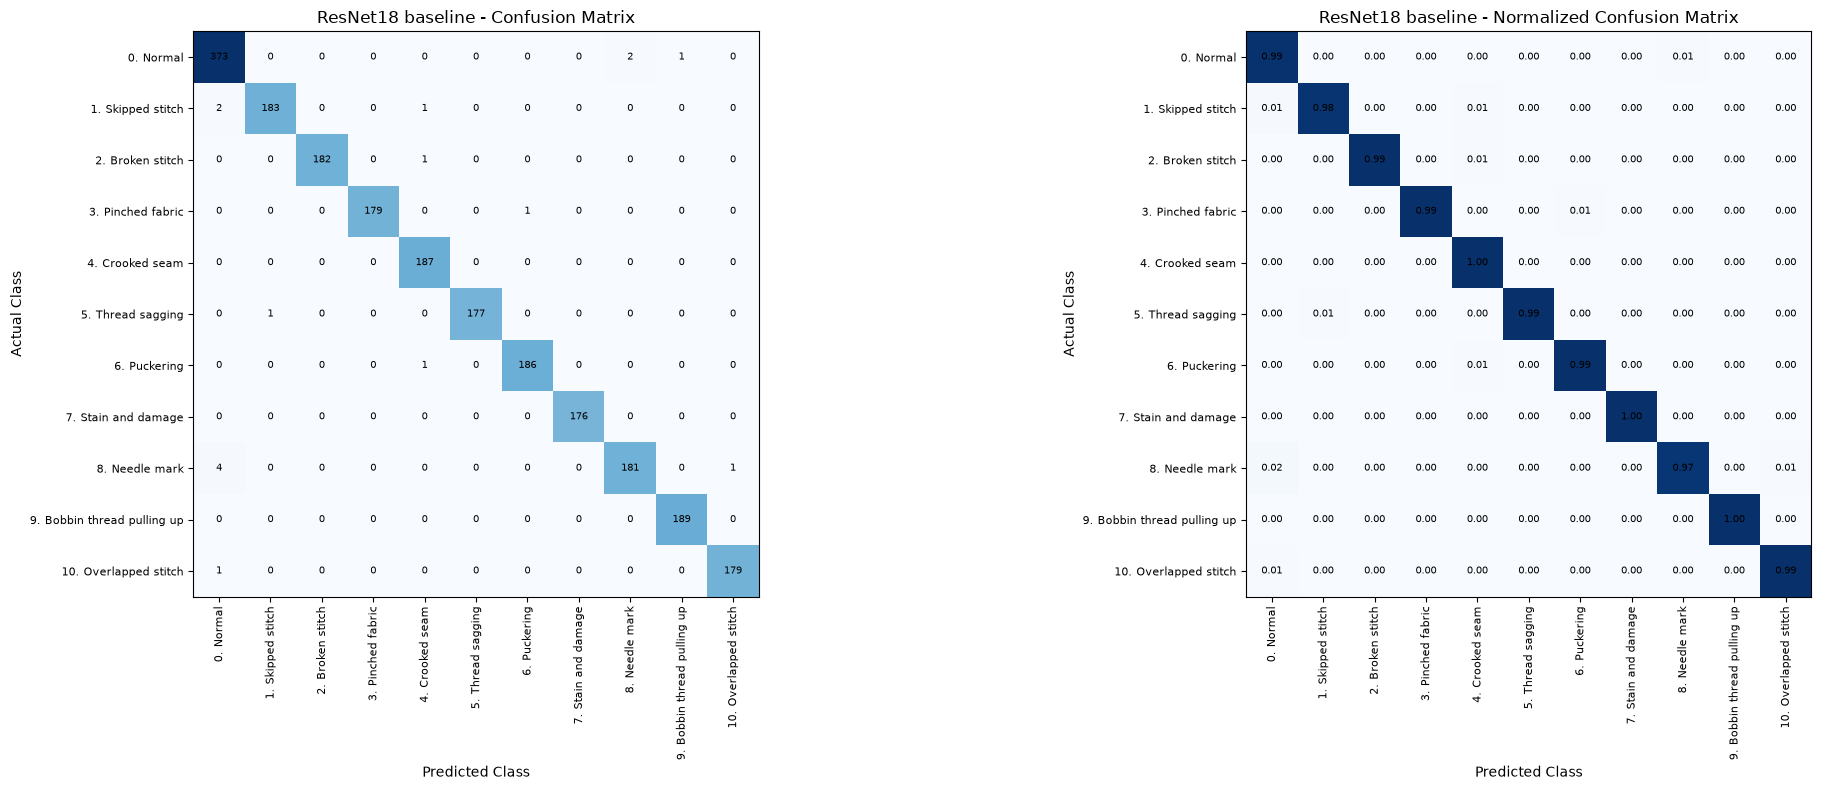

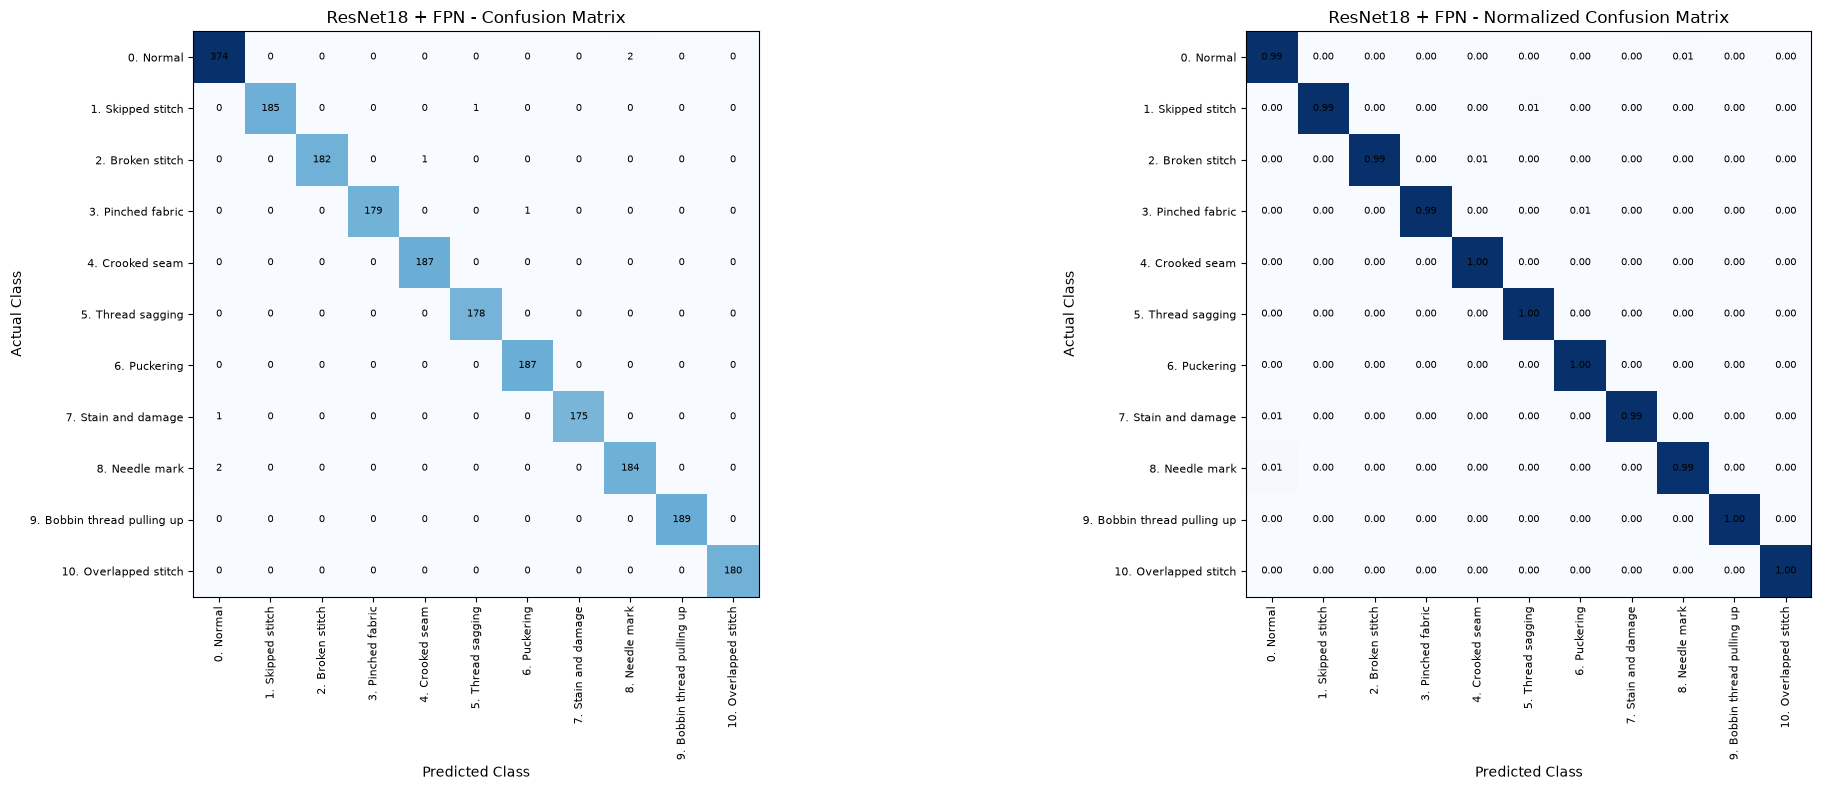

In [27]:

# ============================================================
# CONFUSION MATRIX VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

for name, result in evaluation_results.items():

    cm = result["confusion_matrix"]

    cm_normalized = (
        cm / cm.sum(axis=1, keepdims=True)
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(22, 8)
    )

    # Raw confusion matrix

    axes[0].imshow(cm, cmap="Blues")

    axes[0].set_title(
        f"{name} - Confusion Matrix"
    )

    axes[0].set_xlabel("Predicted Class")
    axes[0].set_ylabel("Actual Class")

    # Normalized confusion matrix

    axes[1].imshow(
        cm_normalized,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    axes[1].set_title(
        f"{name} - Normalized Confusion Matrix"
    )

    axes[1].set_xlabel("Predicted Class")
    axes[1].set_ylabel("Actual Class")

    for ax, matrix, normalized in [
        (axes[0], cm, False),
        (axes[1], cm_normalized, True)
    ]:

        ax.set_xticks(class_labels)
        ax.set_yticks(class_labels)

        ax.set_xticklabels(
            class_label_names,
            rotation=90,
            fontsize=8
        )

        ax.set_yticklabels(
            class_label_names,
            fontsize=8
        )

        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):

                value = (
                    f"{matrix[i, j]:.2f}"
                    if normalized
                    else str(matrix[i, j])
                )

                ax.text(
                    j, i,
                    value,
                    ha="center",
                    va="center",
                    fontsize=7
                )

    plt.tight_layout()
    plt.show()


In [28]:

# ============================================================
# FABRIC-WISE GENERALIZATION EVALUATION
# ============================================================

test_df = (
    split_df[
        split_df["split"] == "test"
    ]
    .reset_index(drop=True)
    .copy()
)

if "class_id" not in test_df.columns:

    test_df["class_id"] = (
        test_df["folder_2"]
        .str.extract(r"^(\d+)")
        .astype(int)
    )

# Ensure metadata corresponds to prediction order.

for name, result in evaluation_results.items():

    y_true = result["y_true"]

    assert len(test_df) == len(y_true), (
        "Test manifest and prediction counts differ."
    )

    assert np.array_equal(
        test_df["class_id"].to_numpy(),
        y_true
    ), (
        "Test manifest order does not match test_loader. "
        "Do not calculate fabric metrics until alignment "
        "has been corrected."
    )

# ------------------------------------------------------------
# Fabric-level accuracy and macro F1
# ------------------------------------------------------------

fabric_results = []

for name, result in evaluation_results.items():

    fabric_data = pd.DataFrame({

        "fabric": test_df["folder_1"].values,

        "actual": result["y_true"],

        "predicted": result["y_pred"]

    })

    for fabric, group in fabric_data.groupby("fabric"):

        fabric_results.append({

            "model": name,

            "fabric": fabric,

            "image_count": len(group),

            "accuracy": accuracy_score(
                group["actual"],
                group["predicted"]
            ),

            "macro_f1": f1_score(
                group["actual"],
                group["predicted"],
                labels=class_labels,
                average="macro",
                zero_division=0
            ),

            "weighted_f1": f1_score(
                group["actual"],
                group["predicted"],
                average="weighted",
                zero_division=0
            )

        })

fabric_results_df = pd.DataFrame(
    fabric_results
)

print("FABRIC-WISE MODEL PERFORMANCE")

display(
    fabric_results_df.pivot(
        index="fabric",
        columns="model",
        values="accuracy"
    ).style.format("{:.4f}")
)

print("\nFULL FABRIC-WISE METRICS")

display(
    fabric_results_df.sort_values(
        ["fabric", "model"]
    )
)


FABRIC-WISE MODEL PERFORMANCE


model,ResNet18 + FPN,ResNet18 baseline
fabric,,
A. Cotton-Poly,1.0000,0.9952
B. Linen-Poly,1.0000,0.9950
C. Denim-Poly,0.9948,1.0000
D. Velveteen-Poly,0.9851,0.9802
E. Polyester-Poly,0.9951,0.9806
F. Satin-Core,1.0000,1.0000
G. Chiffon-Poly,0.9948,0.9844
H. Nylon-Core,1.0000,1.0000
I. Jacquard-Poly,0.9949,0.9949



FULL FABRIC-WISE METRICS


,model,fabric,image_count,accuracy,macro_f1,weighted_f1
11,ResNet18 + FPN,A. Cotton-Poly,210,1.000000,1.000000,1.000000
0,ResNet18 baseline,A. Cotton-Poly,210,0.995238,0.996529,0.995218
12,ResNet18 + FPN,B. Linen-Poly,201,1.000000,1.000000,1.000000
1,ResNet18 baseline,B. Linen-Poly,201,0.995025,0.995847,0.995062
13,ResNet18 + FPN,C. Denim-Poly,192,0.994792,0.995577,0.994750
2,ResNet18 baseline,C. Denim-Poly,192,1.000000,1.000000,1.000000
14,ResNet18 + FPN,D. Velveteen-Poly,202,0.985149,0.989177,0.985255
3,ResNet18 baseline,D. Velveteen-Poly,202,0.980198,0.983514,0.980184
15,ResNet18 + FPN,E. Polyester-Poly,206,0.995146,0.994610,0.995133
4,ResNet18 baseline,E. Polyester-Poly,206,0.980583,0.980709,0.980371


In [29]:

# ============================================================
# COMPLETE MODEL COMPARISON
# ============================================================

training_times = {

    "ResNet18 baseline": 6.582336,

    "ResNet18 + FPN": 7.114116

}

comparison_rows = []

for name, result in evaluation_results.items():

    row = result["metrics"].copy()

    row["training_minutes"] = (
        training_times[name]
    )

    comparison_rows.append(row)

comparison_df = pd.DataFrame(
    comparison_rows
)

# Put important columns first.

priority_columns = [

    "model",

    "test_accuracy",

    "test_macro_f1",
    "test_weighted_f1",

    "macro_precision",
    "macro_recall",

    "balanced_accuracy",

    "matthews_correlation",
    "cohen_kappa",

    "macro_roc_auc_ovr",
    "macro_pr_auc",

    "negative_log_likelihood",
    "multiclass_brier_score",
    "expected_calibration_error",

    "top2_accuracy",

    "parameters",
    "model_size_mb",

    "training_minutes",

    "inference_seconds",
    "avg_latency_ms_per_image",
    "p50_latency_ms_per_image",
    "p95_latency_ms_per_image",

    "throughput_images_per_second",

    "peak_gpu_memory_mb"

]

comparison_df = comparison_df[
    priority_columns
]

print("=" * 80)
print("FINAL ADVANCED MODEL COMPARISON")
print("=" * 80)

display(
    comparison_df.style.format({
        col: "{:.5f}"
        for col in comparison_df.select_dtypes(
            include="number"
        ).columns
        if col != "parameters"
    })
)


FINAL ADVANCED MODEL COMPARISON


,model,test_accuracy,test_macro_f1,test_weighted_f1,macro_precision,macro_recall,balanced_accuracy,matthews_correlation,cohen_kappa,macro_roc_auc_ovr,macro_pr_auc,negative_log_likelihood,multiclass_brier_score,expected_calibration_error,top2_accuracy,parameters,model_size_mb,training_minutes,inference_seconds,avg_latency_ms_per_image,p50_latency_ms_per_image,p95_latency_ms_per_image,throughput_images_per_second,peak_gpu_memory_mb
0,ResNet18 baseline,0.99275,0.99338,0.99275,0.99393,0.99286,0.99286,0.99197,0.99197,0.99994,0.99938,0.11742,0.02031,0.09303,0.99909,11182155,42.69331,6.58234,1.62988,0.73817,0.73035,0.79112,1354.70101,756.66162
1,ResNet18 + FPN,0.99638,0.99667,0.99638,0.99682,0.99653,0.99653,0.99598,0.99598,0.99974,0.99916,0.10626,0.01613,0.08546,0.99819,12024395,45.90620,7.11412,2.17362,0.98443,0.98450,1.01206,1015.81561,1179.16162


In [30]:

# ============================================================
# SAVE ADVANCED EVALUATION RESULTS
# ============================================================

from pathlib import Path

REPORT_DIR = Path(
    "reports/model_evaluation/advanced_resnet18_fpn"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Model comparison

comparison_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

# Per-class results

all_class_results = []

for name, result in evaluation_results.items():

    temp = result["per_class"].copy()

    temp.insert(
        0,
        "model",
        name
    )

    all_class_results.append(temp)

class_results_df = pd.concat(
    all_class_results,
    ignore_index=True
)

class_results_df.to_csv(
    REPORT_DIR / "per_class_metrics.csv",
    index=False
)

# Fabric results

fabric_results_df.to_csv(
    REPORT_DIR / "fabric_wise_metrics.csv",
    index=False
)

# Confusion matrices

for name, result in evaluation_results.items():

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )

    pd.DataFrame(
        result["confusion_matrix"],
        index=class_label_names,
        columns=class_label_names
    ).to_csv(
        REPORT_DIR / f"{safe_name}_confusion_matrix.csv"
    )

# Predictions and errors

for name, result in evaluation_results.items():

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )

    predictions_df = test_df[
        [
            "file_name",
            "s3_key",
            "folder_1",
            "folder_2",
            "class_id"
        ]
    ].copy()

    predictions_df["predicted_class_id"] = (
        result["y_pred"]
    )

    predictions_df["predicted_class"] = [
        class_names[i]
        for i in result["y_pred"]
    ]

    predictions_df["confidence"] = (
        result["y_prob"].max(axis=1)
    )

    predictions_df["correct"] = (
        result["y_true"] == result["y_pred"]
    )

    predictions_df.to_csv(
        REPORT_DIR / f"{safe_name}_predictions.csv",
        index=False
    )

print("ALL EVALUATION REPORTS SAVED")
print("Location:", REPORT_DIR.resolve())

print("\nGenerated files:")

for file in sorted(REPORT_DIR.iterdir()):

    print(
        file.name,
        f"({file.stat().st_size / 1024:.2f} KB)"
    )


ALL EVALUATION REPORTS SAVED
Location: /home/sagemaker-user/stitching-defect-detection/Notebooks/reports/model_evaluation/advanced_resnet18_fpn

Generated files:
fabric_wise_metrics.csv (1.67 KB)
model_comparison.csv (1.26 KB)
per_class_metrics.csv (2.11 KB)
resnet18_baseline_confusion_matrix.csv (0.64 KB)
resnet18_baseline_predictions.csv (308.94 KB)
resnet18_plus_fpn_confusion_matrix.csv (0.64 KB)
resnet18_plus_fpn_predictions.csv (308.95 KB)


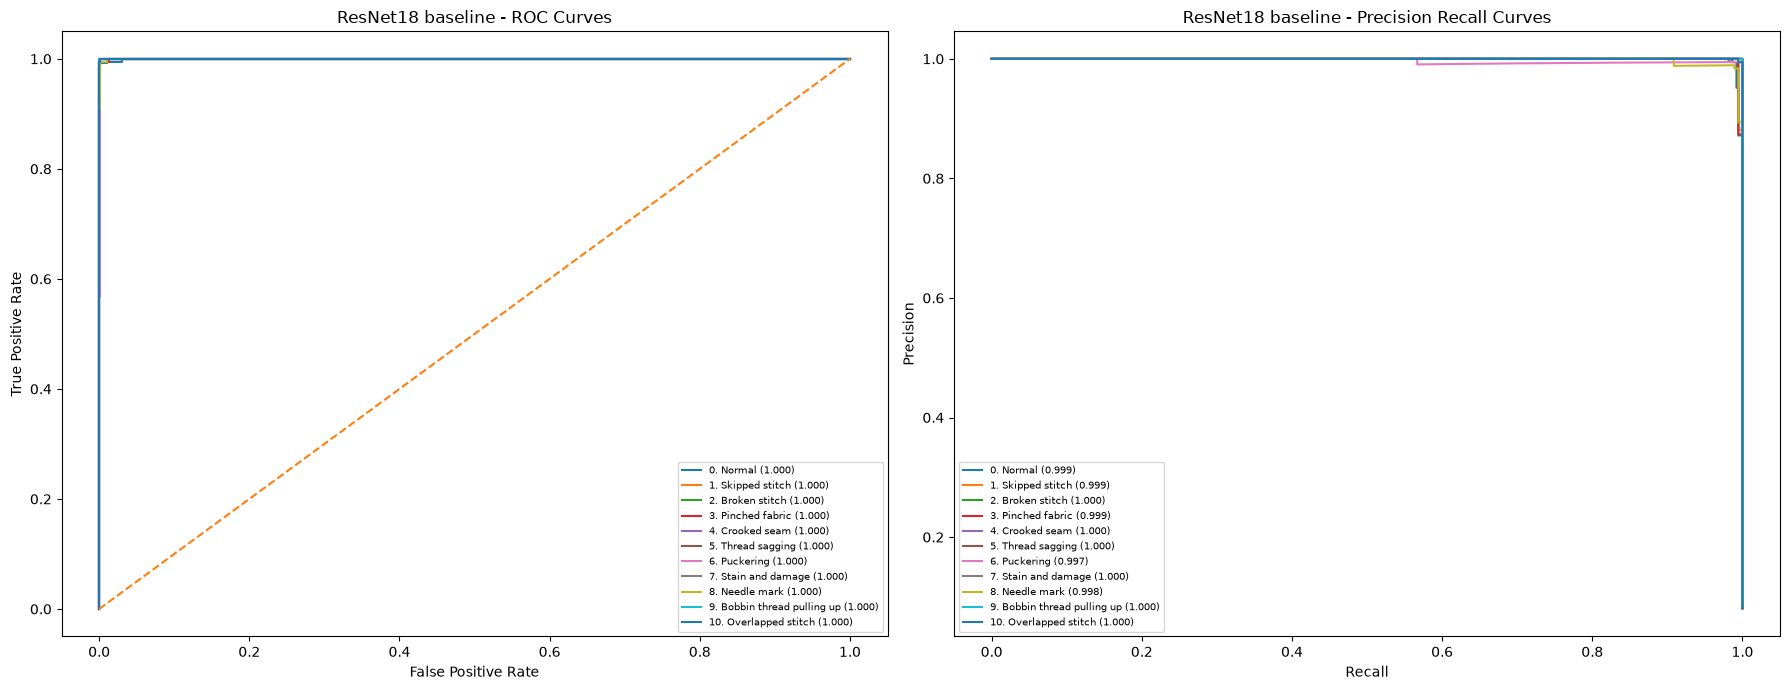

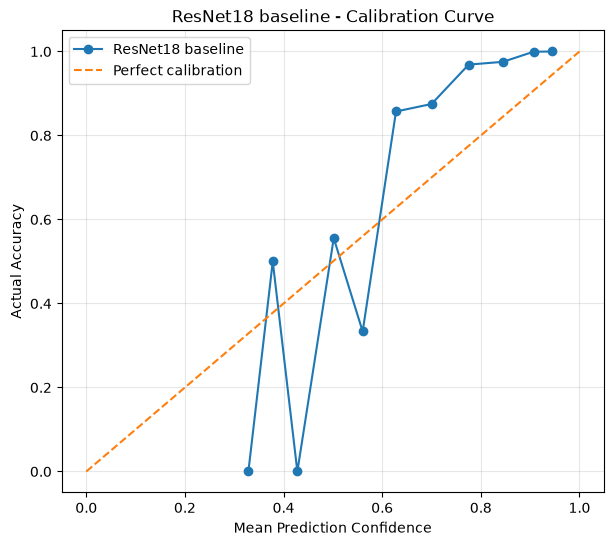

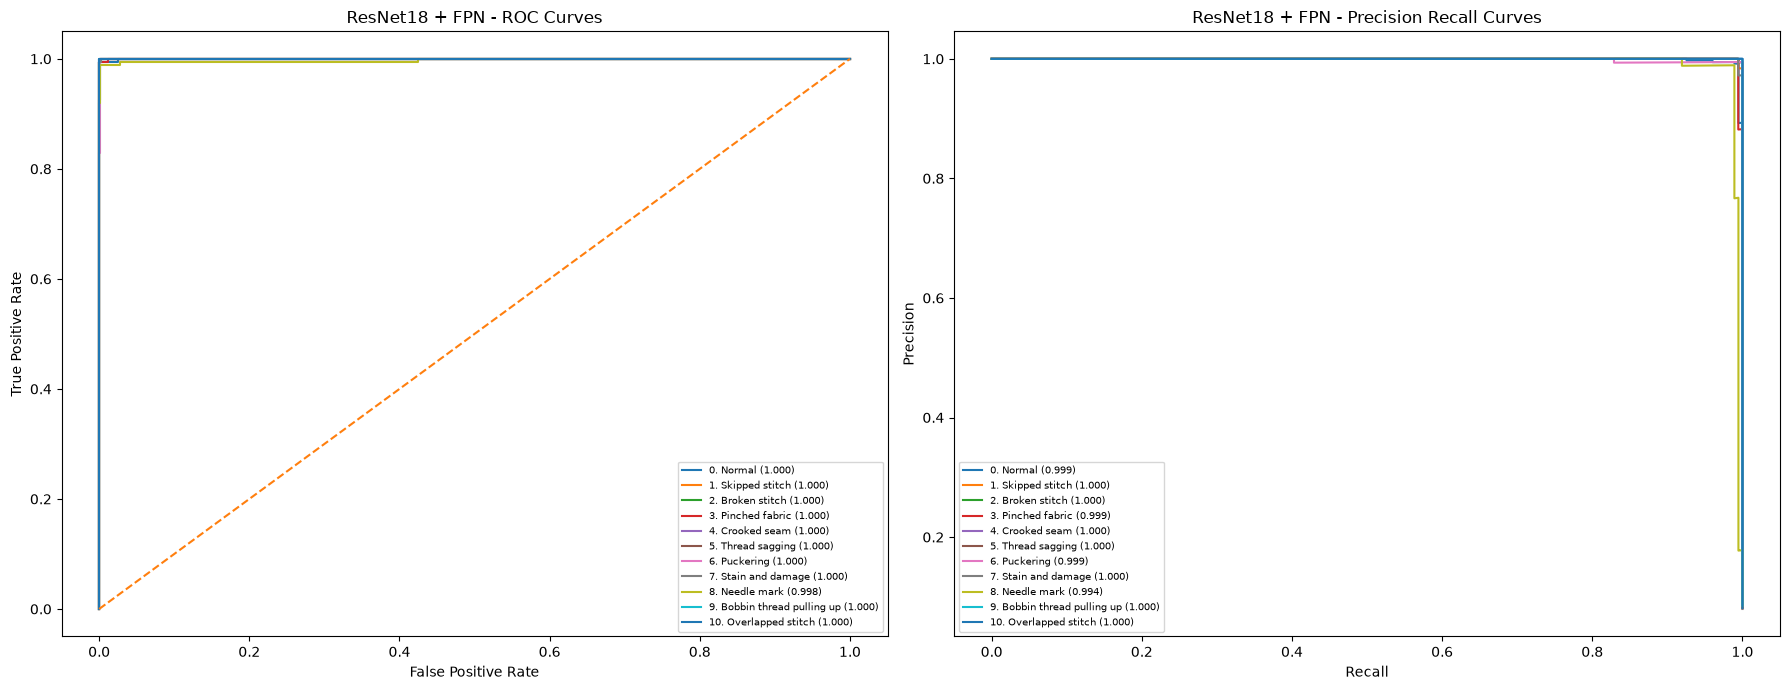

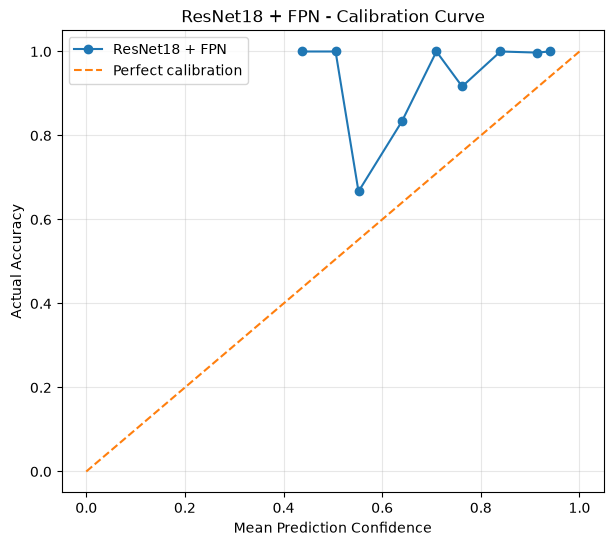

In [31]:

# ============================================================
# ROC, PRECISION-RECALL AND CALIBRATION CURVES
# ============================================================

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

for name, result in evaluation_results.items():

    y_true = result["y_true"]
    y_prob = result["y_prob"]

    one_hot = np.eye(NUM_CLASSES)[y_true]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(18, 7)
    )

    # --------------------------------------------------------
    # ROC curves
    # --------------------------------------------------------

    for i in class_labels:

        fpr, tpr, _ = roc_curve(
            one_hot[:, i],
            y_prob[:, i]
        )

        roc_auc = auc(fpr, tpr)

        axes[0].plot(
            fpr,
            tpr,
            label=f"{class_names[i]} ({roc_auc:.3f})"
        )

    axes[0].plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    axes[0].set_title(
        f"{name} - ROC Curves"
    )

    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")

    axes[0].legend(
        fontsize=7,
        loc="lower right"
    )

    # --------------------------------------------------------
    # Precision-Recall curves
    # --------------------------------------------------------

    for i in class_labels:

        precision, recall, _ = (
            precision_recall_curve(
                one_hot[:, i],
                y_prob[:, i]
            )
        )

        pr_auc = auc(recall, precision)

        axes[1].plot(
            recall,
            precision,
            label=f"{class_names[i]} ({pr_auc:.3f})"
        )

    axes[1].set_title(
        f"{name} - Precision Recall Curves"
    )

    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")

    axes[1].legend(
        fontsize=7,
        loc="lower left"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Calibration curve
    # --------------------------------------------------------

    confidence = y_prob.max(axis=1)

    predicted = y_prob.argmax(axis=1)

    correct = (
        predicted == y_true
    ).astype(float)

    bin_edges = np.linspace(0, 1, 16)

    mean_confidence = []
    mean_accuracy = []

    for i in range(15):

        mask = (
            (confidence >= bin_edges[i]) &
            (
                confidence <= bin_edges[i + 1]
                if i == 14
                else confidence < bin_edges[i + 1]
            )
        )

        if mask.sum() == 0:
            continue

        mean_confidence.append(
            confidence[mask].mean()
        )

        mean_accuracy.append(
            correct[mask].mean()
        )

    plt.figure(figsize=(7, 6))

    plt.plot(
        mean_confidence,
        mean_accuracy,
        marker="o",
        label=name
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    plt.xlabel("Mean Prediction Confidence")
    plt.ylabel("Actual Accuracy")

    plt.title(
        f"{name} - Calibration Curve"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


In [32]:

# ============================================================
# ERROR ANALYSIS
# ============================================================

for name, result in evaluation_results.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    errors = np.where(
        y_true != y_pred
    )[0]

    error_df = test_df.iloc[errors][
        [
            "file_name",
            "s3_key",
            "folder_1",
            "folder_2"
        ]
    ].copy()

    error_df["actual_class"] = [
        class_names[i] for i in y_true[errors]
    ]

    error_df["predicted_class"] = [
        class_names[i] for i in y_pred[errors]
    ]

    error_df["confidence"] = (
        y_prob[errors].max(axis=1)
    )

    error_df["actual_class_probability"] = (
        y_prob[errors, y_true[errors]]
    )

    error_df = error_df.sort_values(
        "confidence",
        ascending=False
    )

    print("\n" + "=" * 70)
    print(name)
    print("Incorrect predictions:", len(errors))
    print("=" * 70)

    display(error_df)

    # Save detailed errors

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )

    error_df.to_csv(
        REPORT_DIR / f"{safe_name}_error_analysis.csv",
        index=False
    )



ResNet18 baseline
Incorrect predictions: 16


,file_name,s3_key,folder_1,folder_2,actual_class,predicted_class,confidence,actual_class_probability
1886,E_03_001.jpg,data/E. Polyester-Poly/3. Pinched fabric/E_03_...,E. Polyester-Poly,3. Pinched fabric,3. Pinched fabric,6. Puckering,0.908629,0.020801
27,D_00_170.jpg,data/D. Velveteen-Poly/0. Normal/D_00_170.jpg,D. Velveteen-Poly,0. Normal,0. Normal,8. Needle mark,0.826973,0.030603
1966,D_00_068.jpg,data/D. Velveteen-Poly/0. Normal/D_00_068.jpg,D. Velveteen-Poly,0. Normal,0. Normal,8. Needle mark,0.826973,0.030603
1595,D_08_080.jpg,data/D. Velveteen-Poly/8. Needle mark/D_08_080...,D. Velveteen-Poly,8. Needle mark,8. Needle mark,0. Normal,0.820588,0.039630
1385,J_01_052.jpg,data/J. Oxford-Core/1. Skipped stitch/J_01_052...,J. Oxford-Core,1. Skipped stitch,1. Skipped stitch,0. Normal,0.780554,0.034331
796,E_08_052.jpg,data/E. Polyester-Poly/8. Needle mark/E_08_052...,E. Polyester-Poly,8. Needle mark,8. Needle mark,0. Normal,0.698131,0.144977
2062,E_05_030.jpg,data/E. Polyester-Poly/5. Thread sagging/E_05_...,E. Polyester-Poly,5. Thread sagging,5. Thread sagging,1. Skipped stitch,0.600565,0.203005
1030,E_08_063.jpg,data/E. Polyester-Poly/8. Needle mark/E_08_063...,E. Polyester-Poly,8. Needle mark,8. Needle mark,0. Normal,0.590477,0.285217
1769,A_01_143.jpg,data/A. Cotton-Poly/1. Skipped stitch/A_01_143...,A. Cotton-Poly,1. Skipped stitch,1. Skipped stitch,0. Normal,0.544392,0.298568
2035,D_08_094.jpg,data/D. Velveteen-Poly/8. Needle mark/D_08_094...,D. Velveteen-Poly,8. Needle mark,8. Needle mark,10. Overlapped stitch,0.520478,0.311668



ResNet18 + FPN
Incorrect predictions: 8


,file_name,s3_key,folder_1,folder_2,actual_class,predicted_class,confidence,actual_class_probability
1595,D_08_080.jpg,data/D. Velveteen-Poly/8. Needle mark/D_08_080...,D. Velveteen-Poly,8. Needle mark,8. Needle mark,0. Normal,0.907068,0.008407
1895,I_08_109.jpg,data/I. Jacquard-Poly/8. Needle mark/I_08_109.jpg,I. Jacquard-Poly,8. Needle mark,8. Needle mark,0. Normal,0.897934,0.019052
27,D_00_170.jpg,data/D. Velveteen-Poly/0. Normal/D_00_170.jpg,D. Velveteen-Poly,0. Normal,0. Normal,8. Needle mark,0.886098,0.017649
1966,D_00_068.jpg,data/D. Velveteen-Poly/0. Normal/D_00_068.jpg,D. Velveteen-Poly,0. Normal,0. Normal,8. Needle mark,0.886098,0.017649
1886,E_03_001.jpg,data/E. Polyester-Poly/3. Pinched fabric/E_03_...,E. Polyester-Poly,3. Pinched fabric,3. Pinched fabric,6. Puckering,0.878932,0.022371
321,C_07_031.jpg,data/C. Denim-Poly/7. Stain and damage/C_07_03...,C. Denim-Poly,7. Stain and damage,7. Stain and damage,0. Normal,0.746938,0.058640
1423,G_02_050.jpg,data/G. Chiffon-Poly/2. Broken stitch/G_02_050...,G. Chiffon-Poly,2. Broken stitch,2. Broken stitch,4. Crooked seam,0.611454,0.190689
1385,J_01_052.jpg,data/J. Oxford-Core/1. Skipped stitch/J_01_052...,J. Oxford-Core,1. Skipped stitch,1. Skipped stitch,5. Thread sagging,0.561050,0.073010


In [36]:

# ============================================================
# RESNET18 + FPN - COMPLETE MODEL COMPARISON REPORT
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Verify evaluation results are available
# ------------------------------------------------------------

required_objects = [
    "all_metrics_df",
    "all_class_metrics_df",
    "all_fabric_metrics_df"
]

for name in required_objects:
    assert name in globals(), (
        f"{name} is missing. Run the model evaluation cells first."
    )

# ------------------------------------------------------------
# 2. Identify ResNet18 + FPN
# ------------------------------------------------------------

def select_resnet(df):

    model_names = df["model"].astype(str)

    mask = (
        model_names.str.contains(
            "resnet18",
            case=False,
            regex=False
        )
        &
        model_names.str.contains(
            "fpn",
            case=False,
            regex=False
        )
    )

    return df[mask].copy()


resnet_metrics = select_resnet(all_metrics_df)
resnet_class = select_resnet(all_class_metrics_df)
resnet_fabric = select_resnet(all_fabric_metrics_df)

assert len(resnet_metrics) > 0, (
    "ResNet18 + FPN not found in aggregate evaluation results. "
    "Check the model names in all_metrics_df."
)

# ------------------------------------------------------------
# 3. Aggregate classification performance
# ------------------------------------------------------------

main_metrics = [
    "model",
    "split",
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "mcc",
    "cohen_kappa",
    "macro_roc_auc",
    "macro_pr_auc",
    "top2_accuracy"
]

available = [
    c for c in main_metrics
    if c in resnet_metrics.columns
]

print("=" * 85)
print("RESNET18 + FPN: CLASSIFICATION PERFORMANCE")
print("=" * 85)

display(
    resnet_metrics[available]
    .sort_values("split")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Confidence and calibration
# ------------------------------------------------------------

calibration_metrics = [
    "model",
    "split",
    "ece",
    "log_loss",
    "negative_log_likelihood",
    "multiclass_brier_score"
]

available = [
    c for c in calibration_metrics
    if c in resnet_metrics.columns
]

print("\nCONFIDENCE AND CALIBRATION")

display(
    resnet_metrics[available]
)

# ------------------------------------------------------------
# 5. Individual defect performance
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("RESNET18 + FPN: PER-DEFECT PERFORMANCE")
print("=" * 85)

class_columns = [
    c for c in [
        "model",
        "split",
        "class_id",
        "class_name",
        "class",
        "precision",
        "recall",
        "f1_score",
        "support"
    ]
    if c in resnet_class.columns
]

display(
    resnet_class[class_columns]
    .sort_values(
        [c for c in ["split", "class_id"]
         if c in class_columns]
    )
    .reset_index(drop=True)
)

# Identify weakest defects by recall

if "recall" in resnet_class.columns:

    for split_name in ["validation", "test"]:

        subset = resnet_class[
            resnet_class["split"] == split_name
        ]

        if len(subset):

            print(
                f"\nLowest defect recall: {split_name}"
            )

            display(
                subset.sort_values("recall")
                .head(5)[class_columns]
            )

# ------------------------------------------------------------
# 6. Fabric-wise generalization
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("RESNET18 + FPN: FABRIC-WISE PERFORMANCE")
print("=" * 85)

fabric_columns = [
    c for c in [
        "model",
        "split",
        "fabric",
        "macro_f1",
        "accuracy",
        "macro_recall",
        "macro_precision"
    ]
    if c in resnet_fabric.columns
]

display(
    resnet_fabric[fabric_columns]
    .sort_values(
        [c for c in ["split", "macro_f1"]
         if c in fabric_columns],
        ascending=[
            True if c == "split" else True
            for c in ["split", "macro_f1"]
            if c in fabric_columns
        ]
    )
    .reset_index(drop=True)
)

# Worst fabric for each split

if "macro_f1" in resnet_fabric.columns:

    for split_name in ["validation", "test"]:

        subset = resnet_fabric[
            resnet_fabric["split"] == split_name
        ]

        if len(subset):

            worst = subset.loc[
                subset["macro_f1"].idxmin()
            ]

            print(
                f"\nWorst fabric ({split_name}):",
                worst.get("fabric", "Unknown"),
                "| Macro F1:",
                round(worst["macro_f1"], 6)
            )

# ------------------------------------------------------------
# 7. Compare all architectures side by side
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("ALL ARCHITECTURES: VALIDATION VS TEST")
print("=" * 85)

comparison_columns = [
    c for c in [
        "model",
        "split",
        "accuracy",
        "macro_f1",
        "balanced_accuracy",
        "macro_precision",
        "macro_recall",
        "mcc",
        "ece",
        "log_loss",
        "multiclass_brier_score",
        "worst_fabric_macro_f1"
    ]
    if c in all_metrics_df.columns
]

display(
    all_metrics_df[comparison_columns]
    .sort_values(
        ["split", "macro_f1"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 8. Check missing validation/test results
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("EVALUATION COMPLETENESS")
print("=" * 85)

for name, df in [
    ("Aggregate metrics", resnet_metrics),
    ("Per-defect metrics", resnet_class),
    ("Per-fabric metrics", resnet_fabric)
]:

    available_splits = set(df["split"].unique())

    print(
        name,
        "| Validation:",
        "AVAILABLE" if "validation" in available_splits else "MISSING",
        "| Test:",
        "AVAILABLE" if "test" in available_splits else "MISSING"
    )

print("\nRESNET18 + FPN REPORT COMPLETED.")


RESNET18 + FPN: CLASSIFICATION PERFORMANCE


,model,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,balanced_accuracy,mcc,cohen_kappa,macro_roc_auc,macro_pr_auc,top2_accuracy
0,ResNet18 + FPN,test,0.996377,0.996824,0.996532,0.996673,0.996378,0.996532,0.995984,0.995984,0.999739,0.999158,0.998188



CONFIDENCE AND CALIBRATION


,model,split,ece,log_loss,negative_log_likelihood,multiclass_brier_score
1,ResNet18 + FPN,test,0.085456,0.106256,0.106256,0.016134



RESNET18 + FPN: PER-DEFECT PERFORMANCE


,model,split,class_id,class_name,precision,recall,f1_score,support
0,ResNet18 + FPN,test,0,0. Normal,0.992042,0.994681,0.993360,376
1,ResNet18 + FPN,test,1,1. Skipped stitch,1.000000,0.994624,0.997305,186
2,ResNet18 + FPN,test,2,2. Broken stitch,1.000000,0.994536,0.997260,183
3,ResNet18 + FPN,test,3,3. Pinched fabric,1.000000,0.994444,0.997214,180
4,ResNet18 + FPN,test,4,4. Crooked seam,0.994681,1.000000,0.997333,187
5,ResNet18 + FPN,test,5,5. Thread sagging,0.994413,1.000000,0.997199,178
6,ResNet18 + FPN,test,6,6. Puckering,0.994681,1.000000,0.997333,187
7,ResNet18 + FPN,test,7,7. Stain and damage,1.000000,0.994318,0.997151,176
8,ResNet18 + FPN,test,8,8. Needle mark,0.989247,0.989247,0.989247,186
9,ResNet18 + FPN,test,9,9. Bobbin thread pulling up,1.000000,1.000000,1.000000,189


... (3 outputs left out)

,model,split,fabric,macro_f1,accuracy,macro_recall,macro_precision
0,ResNet18 + FPN,test,D. Velveteen-Poly,0.989177,0.985149,0.990404,0.988100
1,ResNet18 + FPN,test,G. Chiffon-Poly,0.994268,0.994792,0.993939,0.994949
2,ResNet18 + FPN,test,E. Polyester-Poly,0.994610,0.995146,0.994318,0.995215
3,ResNet18 + FPN,test,J. Oxford-Core,0.994788,0.995305,0.995215,0.994652
4,ResNet18 + FPN,test,C. Denim-Poly,0.995577,0.994792,0.994318,0.997067
5,ResNet18 + FPN,test,I. Jacquard-Poly,0.995577,0.994872,0.994318,0.997067
6,ResNet18 + FPN,test,A. Cotton-Poly,1.000000,1.000000,1.000000,1.000000
7,ResNet18 + FPN,test,B. Linen-Poly,1.000000,1.000000,1.000000,1.000000
8,ResNet18 + FPN,test,F. Satin-Core,1.000000,1.000000,1.000000,1.000000
9,ResNet18 + FPN,test,H. Nylon-Core,1.000000,1.000000,1.000000,1.000000



Worst fabric (test): D. Velveteen-Poly | Macro F1: 0.989177

ALL ARCHITECTURES: VALIDATION VS TEST


,model,split,accuracy,macro_f1,balanced_accuracy,macro_precision,macro_recall,mcc,ece,log_loss,multiclass_brier_score,worst_fabric_macro_f1
0,ResNet18 + FPN,test,0.996377,0.996673,0.996532,0.996824,0.996532,0.995984,0.085456,0.106256,0.016134,0.989177
1,ResNet18 baseline,test,0.992754,0.993377,0.992861,0.993933,0.992861,0.991971,0.093028,0.117418,0.020314,0.980709



EVALUATION COMPLETENESS
Aggregate metrics | Validation: MISSING | Test: AVAILABLE
Per-defect metrics | Validation: MISSING | Test: AVAILABLE
Per-fabric metrics | Validation: MISSING | Test: AVAILABLE

RESNET18 + FPN REPORT COMPLETED.


In [35]:

# ============================================================
# BUILD AGGREGATE EVALUATION DATAFRAMES
#
# Creates all_metrics_df, all_class_metrics_df, all_fabric_metrics_df
# from evaluation_results and test_df produced by the advanced
# evaluation cells above.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. all_metrics_df  (aggregate per-model metrics)
# ------------------------------------------------------------

metrics_rows = []

for model_name, result in evaluation_results.items():

    m = result["metrics"]

    # Worst fabric macro F1 for this model
    fabric_subset = fabric_results_df[
        fabric_results_df["model"] == model_name
    ]

    worst_fabric_f1 = (
        fabric_subset["macro_f1"].min()
        if len(fabric_subset) > 0
        else np.nan
    )

    row = {
        "model": model_name,
        "split": "test",
        "accuracy": m["test_accuracy"],
        "macro_precision": m["macro_precision"],
        "macro_recall": m["macro_recall"],
        "macro_f1": m["test_macro_f1"],
        "weighted_f1": m["test_weighted_f1"],
        "balanced_accuracy": m["balanced_accuracy"],
        "mcc": m["matthews_correlation"],
        "cohen_kappa": m["cohen_kappa"],
        "macro_roc_auc": m["macro_roc_auc_ovr"],
        "macro_pr_auc": m["macro_pr_auc"],
        "top2_accuracy": m["top2_accuracy"],
        "ece": m["expected_calibration_error"],
        "log_loss": m["negative_log_likelihood"],
        "negative_log_likelihood": m["negative_log_likelihood"],
        "multiclass_brier_score": m["multiclass_brier_score"],
        "worst_fabric_macro_f1": worst_fabric_f1
    }

    metrics_rows.append(row)

all_metrics_df = pd.DataFrame(metrics_rows)

# ------------------------------------------------------------
# 2. all_class_metrics_df  (per-class / per-defect)
# ------------------------------------------------------------

class_frames = []

for model_name, result in evaluation_results.items():

    per_class = result["per_class"].copy()
    per_class.insert(0, "split", "test")
    per_class.insert(0, "model", model_name)

    class_frames.append(per_class)

all_class_metrics_df = pd.concat(
    class_frames,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. all_fabric_metrics_df  (per-fabric generalization)
# ------------------------------------------------------------

fabric_rows = []

for model_name, result in evaluation_results.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]

    fabric_data = pd.DataFrame({
        "fabric": test_df["folder_1"].values,
        "actual": y_true,
        "predicted": y_pred
    })

    for fabric, group in fabric_data.groupby("fabric"):

        fabric_rows.append({
            "model": model_name,
            "split": "test",
            "fabric": fabric,
            "image_count": len(group),
            "accuracy": accuracy_score(
                group["actual"],
                group["predicted"]
            ),
            "macro_precision": precision_score(
                group["actual"],
                group["predicted"],
                labels=class_labels,
                average="macro",
                zero_division=0
            ),
            "macro_recall": recall_score(
                group["actual"],
                group["predicted"],
                labels=class_labels,
                average="macro",
                zero_division=0
            ),
            "macro_f1": f1_score(
                group["actual"],
                group["predicted"],
                labels=class_labels,
                average="macro",
                zero_division=0
            )
        })

all_fabric_metrics_df = pd.DataFrame(fabric_rows)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("Built evaluation DataFrames:")
print("  all_metrics_df:       ", all_metrics_df.shape)
print("  all_class_metrics_df:  ", all_class_metrics_df.shape)
print("  all_fabric_metrics_df: ", all_fabric_metrics_df.shape)

print("\nModels in all_metrics_df:")
display(
    all_metrics_df[["model", "split"]]
)

print("\nall_fabric_metrics_df columns:")
print(all_fabric_metrics_df.columns.tolist())

print("\nDataFrame construction complete.")


Built evaluation DataFrames:
  all_metrics_df:        (2, 18)
  all_class_metrics_df:   (22, 9)
  all_fabric_metrics_df:  (22, 8)

Models in all_metrics_df:


,model,split
0,ResNet18 baseline,test
1,ResNet18 + FPN,test



all_fabric_metrics_df columns:
['model', 'split', 'fabric', 'image_count', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1']

DataFrame construction complete.


In [37]:

# ============================================================
# EXPERIMENT 18 - COMPLETE RESNET18 EVALUATION
# Validation + Test | Classification + Generalization
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from contextlib import nullcontext

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

MODEL = baseline_model
MODEL_NAME = "resnet18_baseline"

EVAL_DIR = REPORT_DIR / "complete_evaluation"

EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL = MODEL.to(DEVICE)
MODEL.eval()

LABELS = list(range(NUM_CLASSES))

TARGET_NAMES = [
    class_names[i]
    for i in LABELS
]

# Check checkpoint size
CHECKPOINT_PATH = (
    OUTPUT_DIR /
    f"{MODEL_NAME}_best.pth"
)

MODEL_SIZE_MB = (
    CHECKPOINT_PATH.stat().st_size / 1024**2
    if CHECKPOINT_PATH.exists()
    else np.nan
)

PARAMETERS = sum(
    p.numel()
    for p in MODEL.parameters()
)

TRAINABLE_PARAMETERS = sum(
    p.numel()
    for p in MODEL.parameters()
    if p.requires_grad
)

# ------------------------------------------------------------
# EXPECTED CALIBRATION ERROR
# ------------------------------------------------------------

def calculate_ece(
    probabilities,
    targets,
    bins=15
):

    confidence = probabilities.max(axis=1)

    predictions = probabilities.argmax(axis=1)

    correctness = (
        predictions == targets
    ).astype(float)

    ece = 0.0

    bin_edges = np.linspace(
        0,
        1,
        bins + 1
    )

    for i in range(bins):

        mask = (
            (confidence > bin_edges[i])
            &
            (confidence <= bin_edges[i + 1])
        )

        if mask.sum() == 0:
            continue

        accuracy_bin = correctness[mask].mean()

        confidence_bin = confidence[mask].mean()

        ece += (
            mask.mean()
            * abs(accuracy_bin - confidence_bin)
        )

    return float(ece)


# ------------------------------------------------------------
# FULL METRIC CALCULATION
# ------------------------------------------------------------

def calculate_complete_metrics(
    targets,
    predictions,
    probabilities
):

    one_hot = np.eye(NUM_CLASSES)[targets]

    clipped_probabilities = np.clip(
        probabilities,
        1e-12,
        1.0
    )

    # Top-2 predictions
    top2 = np.argpartition(
        probabilities,
        -2,
        axis=1
    )[:, -2:]

    top2_accuracy = np.mean([
        target in predicted
        for target, predicted in zip(
            targets,
            top2
        )
    ])

    metrics = {

        "accuracy": accuracy_score(
            targets,
            predictions
        ),

        "macro_precision": precision_score(
            targets,
            predictions,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            targets,
            predictions,
            average="macro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            targets,
            predictions,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            targets,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "balanced_accuracy": balanced_accuracy_score(
            targets,
            predictions
        ),

        "mcc": matthews_corrcoef(
            targets,
            predictions
        ),

        "cohen_kappa": cohen_kappa_score(
            targets,
            predictions
        ),

        "negative_log_likelihood": -np.mean(
            np.log(
                clipped_probabilities[
                    np.arange(len(targets)),
                    targets
                ]
            )
        ),

        "multiclass_brier_score": np.mean(
            np.sum(
                (probabilities - one_hot) ** 2,
                axis=1
            )
        ),

        "ece": calculate_ece(
            probabilities,
            targets
        ),

        "top2_accuracy": top2_accuracy
    }

    try:

        metrics["macro_roc_auc"] = roc_auc_score(
            one_hot,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

        metrics["macro_pr_auc"] = average_precision_score(
            one_hot,
            probabilities,
            average="macro"
        )

    except ValueError:

        metrics["macro_roc_auc"] = np.nan
        metrics["macro_pr_auc"] = np.nan

    return metrics


# ------------------------------------------------------------
# EVALUATION ENGINE
# ------------------------------------------------------------

def evaluate_complete(
    model,
    loader,
    split_name
):

    model.eval()

    all_targets = []
    all_predictions = []
    all_probabilities = []

    batch_latencies = []

    if DEVICE.type == "cuda":

        torch.cuda.reset_peak_memory_stats()

    inference_start = time.perf_counter()

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            batch_start = time.perf_counter()

            if AMP_ENABLED:

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    outputs = model(images)

            else:

                outputs = model(images)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            batch_seconds = (
                time.perf_counter()
                - batch_start
            )

            batch_latencies.append(
                batch_seconds * 1000 / len(labels)
            )

            probabilities = torch.softmax(
                outputs.float(),
                dim=1
            )

            predictions = outputs.argmax(
                dim=1
            )

            all_targets.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    inference_seconds = (
        time.perf_counter()
        - inference_start
    )

    targets = np.asarray(all_targets)

    predictions = np.asarray(all_predictions)

    probabilities = np.asarray(all_probabilities)

    assert len(targets) == len(loader.dataset)

    metrics = calculate_complete_metrics(
        targets,
        predictions,
        probabilities
    )

    metrics.update({

        "model": MODEL_NAME,

        "split": split_name,

        "inference_seconds": inference_seconds,

        "avg_latency_ms_per_image": np.mean(
            batch_latencies
        ),

        "p50_latency_ms_per_image": np.percentile(
            batch_latencies,
            50
        ),

        "p95_latency_ms_per_image": np.percentile(
            batch_latencies,
            95
        ),

        "throughput_images_per_second": (
            len(targets) / inference_seconds
        ),

        "parameters": PARAMETERS,

        "trainable_parameters": TRAINABLE_PARAMETERS,

        "model_size_mb": MODEL_SIZE_MB,

        "peak_gpu_memory_mb": (
            torch.cuda.max_memory_allocated() / 1024**2
            if DEVICE.type == "cuda"
            else 0
        )

    })

    # --------------------------------------------------------
    # PER-DEFECT METRICS
    # --------------------------------------------------------

    report = classification_report(
        targets,
        predictions,
        labels=LABELS,
        target_names=TARGET_NAMES,
        output_dict=True,
        zero_division=0
    )

    class_df = (
        pd.DataFrame(report)
        .T
        .iloc[:NUM_CLASSES]
        .reset_index()
        .rename(columns={"index": "class_name"})
    )

    class_df["model"] = MODEL_NAME
    class_df["split"] = split_name

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        targets,
        predictions,
        labels=LABELS
    )

    cm_df = pd.DataFrame(
        cm,
        index=TARGET_NAMES,
        columns=TARGET_NAMES
    )

    # --------------------------------------------------------
    # SAVE PREDICTIONS
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({

        "true_class_id": targets,

        "true_class": [
            class_names[i] for i in targets
        ],

        "predicted_class_id": predictions,

        "predicted_class": [
            class_names[i] for i in predictions
        ],

        "confidence": probabilities.max(axis=1),

        "correct": targets == predictions

    })

    prediction_df.to_csv(
        EVAL_DIR / f"{split_name}_predictions.csv",
        index=False
    )

    class_df.to_csv(
        EVAL_DIR / f"{split_name}_per_class.csv",
        index=False
    )

    cm_df.to_csv(
        EVAL_DIR / f"{split_name}_confusion_matrix.csv"
    )

    # Save probabilities for further analysis.
    np.save(
        EVAL_DIR / f"{split_name}_probabilities.npy",
        probabilities
    )

    print("\n" + "=" * 75)
    print(f"{MODEL_NAME.upper()} | {split_name.upper()}")
    print("=" * 75)

    for key, value in metrics.items():

        if isinstance(value, (float, np.floating)):

            print(
                f"{key:40s}: {value:.6f}"
            )

    print("\nPER-DEFECT PERFORMANCE")

    display(
        class_df[
            [
                "class_name",
                "precision",
                "recall",
                "f1-score",
                "support"
            ]
        ]
    )

    print("\nCONFUSION MATRIX")

    display(cm_df)

    return {
        "metrics": metrics,
        "per_class": class_df,
        "confusion_matrix": cm_df,
        "predictions": prediction_df,
        "probabilities": probabilities,
        "targets": targets
    }


# ------------------------------------------------------------
# RUN VALIDATION AND TEST
# ------------------------------------------------------------

resnet_validation_results = evaluate_complete(
    MODEL,
    validation_loader,
    "validation"
)

resnet_test_results = evaluate_complete(
    MODEL,
    test_loader,
    "test"
)

# ------------------------------------------------------------
# SAVE CONSOLIDATED RESULTS
# ------------------------------------------------------------

resnet_complete_metrics = pd.DataFrame([

    resnet_validation_results["metrics"],

    resnet_test_results["metrics"]

])

resnet_complete_metrics.to_csv(
    EVAL_DIR / "resnet18_complete_metrics.csv",
    index=False
)

resnet_complete_classes = pd.concat([

    resnet_validation_results["per_class"],

    resnet_test_results["per_class"]

], ignore_index=True)

resnet_complete_classes.to_csv(
    EVAL_DIR / "resnet18_all_class_metrics.csv",
    index=False
)

print("\n" + "=" * 75)
print("RESNET18 COMPLETE EVALUATION FINISHED")
print("=" * 75)

display(resnet_complete_metrics)

print("\nSaved reports:", EVAL_DIR)



RESNET18_BASELINE | VALIDATION
accuracy                                : 0.995915
macro_precision                         : 0.997344
macro_recall                            : 0.995533
macro_f1                                : 0.996421
weighted_f1                             : 0.995919
balanced_accuracy                       : 0.995533
mcc                                     : 0.995479
cohen_kappa                             : 0.995472
negative_log_likelihood                 : 0.112462
multiclass_brier_score                  : 0.017520
ece                                     : 0.095176
top2_accuracy                           : 0.998638
macro_roc_auc                           : 0.999967
macro_pr_auc                            : 0.999745
inference_seconds                       : 2.400178
avg_latency_ms_per_image                : 0.797105
p50_latency_ms_per_image                : 0.805799
p95_latency_ms_per_image                : 0.878150
throughput_images_per_second            : 917.8486

,class_name,precision,recall,f1-score,support
0,0. Normal,0.981432,1.000000,0.990629,370.0
1,1. Skipped stitch,1.000000,0.989247,0.994595,186.0
2,2. Broken stitch,1.000000,0.994536,0.997260,183.0
3,3. Pinched fabric,1.000000,1.000000,1.000000,178.0
4,4. Crooked seam,1.000000,1.000000,1.000000,187.0
5,5. Thread sagging,1.000000,0.994318,0.997151,176.0
6,6. Puckering,1.000000,1.000000,1.000000,186.0
7,7. Stain and damage,1.000000,0.988889,0.994413,180.0
8,8. Needle mark,0.994565,0.983871,0.989189,186.0
9,9. Bobbin thread pulling up,0.994792,1.000000,0.997389,191.0



CONFUSION MATRIX


,0. Normal,1. Skipped stitch,2. Broken stitch,3. Pinched fabric,4. Crooked seam,5. Thread sagging,6. Puckering,7. Stain and damage,8. Needle mark,9. Bobbin thread pulling up,10. Overlapped stitch
0. Normal,370,0,0,0,0,0,0,0,0,0,0
1. Skipped stitch,1,184,0,0,0,0,0,0,1,0,0
2. Broken stitch,1,0,182,0,0,0,0,0,0,0,0
3. Pinched fabric,0,0,0,178,0,0,0,0,0,0,0
4. Crooked seam,0,0,0,0,187,0,0,0,0,0,0
5. Thread sagging,1,0,0,0,0,175,0,0,0,0,0
6. Puckering,0,0,0,0,0,0,186,0,0,0,0
7. Stain and damage,1,0,0,0,0,0,0,178,0,1,0
8. Needle mark,3,0,0,0,0,0,0,0,183,0,0
9. Bobbin thread pulling up,0,0,0,0,0,0,0,0,0,191,0



RESNET18_BASELINE | TEST
accuracy                                : 0.992754
macro_precision                         : 0.993933
macro_recall                            : 0.992861
macro_f1                                : 0.993377
weighted_f1                             : 0.992752
balanced_accuracy                       : 0.992861
mcc                                     : 0.991971
cohen_kappa                             : 0.991966
negative_log_likelihood                 : 0.117402
multiclass_brier_score                  : 0.020314
ece                                     : 0.093007
top2_accuracy                           : 0.999094
macro_roc_auc                           : 0.999936
macro_pr_auc                            : 0.999374
inference_seconds                       : 2.316728
avg_latency_ms_per_image                : 0.804569
p50_latency_ms_per_image                : 0.815741
p95_latency_ms_per_image                : 0.902650
throughput_images_per_second            : 953.068213
mod

,class_name,precision,recall,f1-score,support
0,0. Normal,0.981579,0.992021,0.986772,376.0
1,1. Skipped stitch,0.994565,0.983871,0.989189,186.0
2,2. Broken stitch,1.000000,0.994536,0.997260,183.0
3,3. Pinched fabric,1.000000,0.994444,0.997214,180.0
4,4. Crooked seam,0.984211,1.000000,0.992042,187.0
5,5. Thread sagging,1.000000,0.994382,0.997183,178.0
6,6. Puckering,0.994652,0.994652,0.994652,187.0
7,7. Stain and damage,1.000000,1.000000,1.000000,176.0
8,8. Needle mark,0.989071,0.973118,0.981030,186.0
9,9. Bobbin thread pulling up,0.994737,1.000000,0.997361,189.0



CONFUSION MATRIX


,0. Normal,1. Skipped stitch,2. Broken stitch,3. Pinched fabric,4. Crooked seam,5. Thread sagging,6. Puckering,7. Stain and damage,8. Needle mark,9. Bobbin thread pulling up,10. Overlapped stitch
0. Normal,373,0,0,0,0,0,0,0,2,1,0
1. Skipped stitch,2,183,0,0,1,0,0,0,0,0,0
2. Broken stitch,0,0,182,0,1,0,0,0,0,0,0
3. Pinched fabric,0,0,0,179,0,0,1,0,0,0,0
4. Crooked seam,0,0,0,0,187,0,0,0,0,0,0
5. Thread sagging,0,1,0,0,0,177,0,0,0,0,0
6. Puckering,0,0,0,0,1,0,186,0,0,0,0
7. Stain and damage,0,0,0,0,0,0,0,176,0,0,0
8. Needle mark,4,0,0,0,0,0,0,0,181,0,1
9. Bobbin thread pulling up,0,0,0,0,0,0,0,0,0,189,0



RESNET18 COMPLETE EVALUATION FINISHED


,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,balanced_accuracy,mcc,cohen_kappa,negative_log_likelihood,multiclass_brier_score,...,split,inference_seconds,avg_latency_ms_per_image,p50_latency_ms_per_image,p95_latency_ms_per_image,throughput_images_per_second,parameters,trainable_parameters,model_size_mb,peak_gpu_memory_mb
0,0.995915,0.997344,0.995533,0.996421,0.995919,0.995533,0.995479,0.995472,0.112462,0.017520,...,validation,2.400178,0.797105,0.805799,0.87815,917.848661,11182155,11182155,42.736644,548.407227
1,0.992754,0.993933,0.992861,0.993377,0.992752,0.992861,0.991971,0.991966,0.117402,0.020314,...,test,2.316728,0.804569,0.815741,0.90265,953.068213,11182155,11182155,42.736644,548.407227



Saved reports: reports/model_evaluation/advanced_resnet18_fpn/complete_evaluation
